# 🧬 GlucoProfile — Nettoyage et Analyse de la qualité des données

## Objectif

Ce notebook constitue la première étape du projet **GlucoProfile**.

L'objectif est de préparer un jeu de données cliniques contenant les caractéristiques suivantes :

- Pregnancies
- Glucose
- BloodPressure
- SkinThickness
- Insulin
- BMI
- DiabetesPedigreeFunction
- Age

Le dataset est destiné à deux étapes de Machine Learning :

1. **Clustering non supervisé** avec K-Means afin d'identifier des profils similaires de patients.
2. **Classification supervisée** à partir des groupes générés par le clustering.

Dans ce notebook, nous allons :

- charger les données ;
- comprendre leur structure ;
- vérifier les types et les dimensions ;
- détecter les valeurs manquantes ;
- identifier les valeurs codées sous forme de `0` mais représentant en réalité des mesures manquantes ;
- détecter les doublons ;
- détecter les valeurs aberrantes avec la méthode IQR ;
- étudier les distributions et les relations entre variables ;
- comparer plusieurs stratégies d'imputation ;
- construire le dataset final nettoyé ;
- vérifier sa qualité ;
- sauvegarder le dataset propre.

> Important :
> aucune variable `Outcome` n'est utilisée dans ce notebook.
> Le projet doit découvrir les profils de patients de manière non supervisée.

## 1. Importation des bibliothèques

Nous importons les bibliothèques nécessaires au chargement, au nettoyage, à l'analyse statistique et à la visualisation des données.

In [48]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

## 2. Configuration du projet

Nous centralisons les chemins afin d'éviter les chemins absolus et de rendre le notebook reproductible.

Structure attendue :

```text
GlucoProfile/
│
├── data/
│   ├── raw/
│   │   └── diabetes.csv
│   │
│   └── processed/
│       └── diabetes_cleaned.csv
│
├── notebooks/
│   └── 01_cleaning.ipynb
│
└── ...

In [26]:
PROJECT_ROOT = Path.cwd().resolve().parent

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "diabetes.csv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"

PROCESSED_DATA_PATH = PROCESSED_DIR / "diabetes_cleaned.csv"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root :", PROJECT_ROOT)
print("Raw dataset  :", RAW_DATA_PATH)
print("Output path  :", PROCESSED_DATA_PATH)

Project root : /home/badr-eddine-slaoui/Documents/GlucoProfile
Raw dataset  : /home/badr-eddine-slaoui/Documents/GlucoProfile/data/raw/diabetes.csv
Output path  : /home/badr-eddine-slaoui/Documents/GlucoProfile/data/processed/diabetes_cleaned.csv


## 3. Chargement des données

Nous chargeons le fichier CSV avec `pandas`.

À ce stade, aucune transformation n'est encore appliquée. Nous voulons conserver une représentation fidèle des données originales afin de pouvoir comparer l'état initial et l'état final.

In [27]:
df_raw = pd.read_csv(RAW_DATA_PATH)

print(f"Nombre de lignes  : {df_raw.shape[0]}")
print(f"Nombre de colonnes: {df_raw.shape[1]}")

df_raw.head()

Nombre de lignes  : 768
Nombre de colonnes: 9


,Unnamed: 0,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0,6,148,72,35,0,33.6,0.627,50
1,1,1,85,66,29,0,26.6,0.351,31
2,2,8,183,64,0,0,23.3,0.672,32
3,3,1,89,66,23,94,28.1,0.167,21
4,4,0,137,40,35,168,43.1,2.288,33


## 4. Vérification des noms de colonnes

Le fichier fourni contient une première colonne correspondant à l'index CSV ainsi que des caractères `*` dans certains noms de colonnes.

Ces caractères ne représentent pas des variables et doivent être supprimés.

La première colonne d'index ne doit pas être utilisée comme feature ML.

In [28]:
print("Colonnes originales :")
print(df_raw.columns.tolist())

Colonnes originales :
['Unnamed: 0', 'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


In [29]:
df = df_raw.copy()

df.columns = (
    df.columns
    .str.strip()
    .str.replace("*", "", regex=False)
)

unnamed_columns = [
    column
    for column in df.columns
    if column.lower().startswith("unnamed")
]

if unnamed_columns:
    df = df.drop(columns=unnamed_columns)

print("Colonnes après nettoyage :")
print(df.columns.tolist())

Colonnes après nettoyage :
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


## 5. Validation de la structure

Le projet utilise les huit variables cliniques suivantes.

Cette étape permet de détecter immédiatement une colonne manquante, mal nommée ou inattendue.

In [31]:
EXPECTED_FEATURES = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
]

missing_columns = [
    column
    for column in EXPECTED_FEATURES
    if column not in df.columns
]

extra_columns = [
    column
    for column in df.columns
    if column not in EXPECTED_FEATURES
]

print("Colonnes manquantes :", missing_columns)
print("Colonnes supplémentaires :", extra_columns)

Colonnes manquantes : []
Colonnes supplémentaires : []


In [32]:
if missing_columns:
    raise ValueError(
        f"Colonnes obligatoires manquantes : {missing_columns}"
    )

df = df[EXPECTED_FEATURES].copy()

print(f"Dataset final utilisé : {df.shape[0]} lignes × {df.shape[1]} colonnes")

Dataset final utilisé : 768 lignes × 8 colonnes


## 6. Aperçu général du dataset

Nous vérifions maintenant :

- les premières observations ;
- les dernières observations ;
- les dimensions ;
- les types de données ;
- les informations générales ;
- les statistiques descriptives.

Cette étape permet de détecter les premiers problèmes de qualité.

In [33]:
print("Dataset head :")
display(df.head())
print("Dataset tail :")
display(df.tail())
print("Dimensions :", df.shape)
print("Types de données :", df.dtypes)
print("Informations sur le dataset :")
df.info()
print("Statistiques descriptives :")
display(df.describe())
print("Statistiques descriptives transposées :")
display(df.describe().T)

Dataset head :


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33


Dataset tail :


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
763,10,101,76,48,180,32.9,0.171,63
764,2,122,70,27,0,36.8,0.340,27
765,5,121,72,23,112,26.2,0.245,30
766,1,126,60,0,0,30.1,0.349,47
767,1,93,70,31,0,30.4,0.315,23


Dimensions : (768, 8)
Types de données : Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
dtype: object
Informations sur le dataset :
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000


Statistiques descriptives transposées :


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00


## 7. Vérification et conversion des types

Toutes les variables utilisées dans le projet sont numériques.

Nous vérifions leur type afin de détecter d'éventuelles colonnes contenant des valeurs non numériques.

Les valeurs impossibles à convertir seront transformées en `NaN` grâce à `errors="coerce"`.

Cette étape permet d'intégrer automatiquement les éventuelles erreurs de format dans notre traitement des valeurs manquantes.

In [34]:
for column in EXPECTED_FEATURES:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

print("Types des variables :")
print(df.dtypes)

Types des variables :
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
dtype: object


## 8. Détection des valeurs manquantes explicites

Nous commençons par rechercher les valeurs déjà représentées sous forme de `NaN`.

Cette étape est effectuée avant toute autre transformation afin d'obtenir une première estimation de la qualité du dataset.

Nous calculons :

- le nombre de valeurs manquantes par variable ;
- le pourcentage de valeurs manquantes par variable.

In [35]:
missing_report_raw = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (
        df.isna().mean() * 100
    )
}).sort_values(
    by="missing_percentage",
    ascending=False
)

display(missing_report_raw)

,missing_count,missing_percentage
Pregnancies,0,0.0
Glucose,0,0.0
BloodPressure,0,0.0
SkinThickness,0,0.0
Insulin,0,0.0
BMI,0,0.0
DiabetesPedigreeFunction,0,0.0
Age,0,0.0


## 9. Identification des valeurs `0` représentant des données manquantes

L'absence de `NaN` dans le dataset ne signifie pas nécessairement que toutes les observations sont complètes.

Dans ce jeu de données, certaines variables contiennent des `0` qui ne représentent pas une mesure clinique valide.

Les variables concernées sont :

- `Glucose`
- `BloodPressure`
- `SkinThickness`
- `Insulin`
- `BMI`

Pour ces variables, `0` est donc interprété comme une mesure manquante.

En revanche :

- `Pregnancies = 0` est une valeur valide ;
- `Age = 0` serait invalide mais n'est pas utilisé comme valeur manquante codée ;
- `DiabetesPedigreeFunction = 0` n'est pas automatiquement considéré comme manquant.

Cette distinction est importante afin de ne pas supprimer ou modifier les observations valides.

In [36]:
ZERO_AS_MISSING = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
]

zero_report = pd.DataFrame({
    "zero_count": (
        df[ZERO_AS_MISSING] == 0
    ).sum(),

    "zero_percentage": (
        (df[ZERO_AS_MISSING] == 0).mean() * 100
    )
})

display(zero_report)

,zero_count,zero_percentage
Glucose,5,0.651042
BloodPressure,35,4.557292
SkinThickness,227,29.557292
Insulin,374,48.697917
BMI,11,1.432292


## 10. Conversion des valeurs `0` invalides en `NaN`

Les zéros identifiés comme représentant des données manquantes sont convertis en `NaN`.

Cette représentation uniforme permet ensuite d'utiliser les méthodes d'imputation de manière cohérente.

À partir de cette étape :

- une vraie absence de mesure est représentée par `NaN` ;
- un zéro réellement valide reste `0`.

In [37]:
df_clean = df.copy()

for column in ZERO_AS_MISSING:
    df_clean[column] = df_clean[column].replace(
        0,
        np.nan
    )

display(df_clean.head())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33


## 11. Analyse des patterns de valeurs manquantes

Après conversion des zéros invalides en `NaN`, nous analysons plus précisément la structure des données manquantes.

Nous allons :

- compter les valeurs manquantes par variable ;
- calculer le nombre de valeurs manquantes par observation ;
- identifier les observations complètement renseignées ;
- identifier les observations contenant plusieurs variables manquantes.

Cette analyse nous aidera à déterminer si une imputation multivariée comme KNN peut être pertinente.

In [38]:
missing_summary = pd.DataFrame({
    "missing_count": df_clean.isna().sum(),
    "missing_percentage": (
        df_clean.isna().mean() * 100
    )
}).sort_values(
    by="missing_percentage",
    ascending=False
)

display(missing_summary)

,missing_count,missing_percentage
Insulin,374,48.697917
SkinThickness,227,29.557292
BloodPressure,35,4.557292
BMI,11,1.432292
Glucose,5,0.651042
Pregnancies,0,0.000000
DiabetesPedigreeFunction,0,0.000000
Age,0,0.000000


In [39]:
missing_per_row = df_clean.isna().sum(axis=1)

print(
    "Nombre d'observations sans aucune valeur manquante :",
    (missing_per_row == 0).sum()
)

print(
    "Nombre d'observations avec au moins une valeur manquante :",
    (missing_per_row > 0).sum()
)

print(
    "Nombre maximal de valeurs manquantes dans une observation :",
    missing_per_row.max()
)

Nombre d'observations sans aucune valeur manquante : 392
Nombre d'observations avec au moins une valeur manquante : 376
Nombre maximal de valeurs manquantes dans une observation : 4


In [40]:
missing_pattern_report = (
    missing_per_row
    .value_counts()
    .sort_index()
    .rename_axis("missing_values_per_row")
    .reset_index(name="row_count")
)

display(missing_pattern_report)

,missing_values_per_row,row_count
0,0,392
1,1,142
2,2,199
3,3,28
4,4,7


## 12. Recherche de valeurs physiologiquement impossibles

Les valeurs aberrantes statistiques et les valeurs invalides sont deux problèmes différents.

Une valeur très élevée peut être une observation réelle.

En revanche, certaines valeurs sont incompatibles avec la définition même de la variable.

Nous recherchons notamment :

- `Pregnancies < 0`
- `Glucose <= 0`
- `BloodPressure <= 0`
- `SkinThickness <= 0`
- `Insulin <= 0`
- `BMI <= 0`
- `DiabetesPedigreeFunction < 0`
- `Age <= 0`

Les zéros déjà convertis en `NaN` ne seront évidemment plus comptés ici.

In [41]:
INVALID_RULES = {
    "Pregnancies": df_clean["Pregnancies"] < 0,
    "Glucose": df_clean["Glucose"] <= 0,
    "BloodPressure": df_clean["BloodPressure"] <= 0,
    "SkinThickness": df_clean["SkinThickness"] <= 0,
    "Insulin": df_clean["Insulin"] <= 0,
    "BMI": df_clean["BMI"] <= 0,
    "DiabetesPedigreeFunction": (
        df_clean["DiabetesPedigreeFunction"] < 0
    ),
    "Age": df_clean["Age"] <= 0,
}

invalid_report = pd.DataFrame.from_dict(
    {
        column: mask.sum()
        for column, mask in INVALID_RULES.items()
    },
    orient="index",
    columns=["invalid_count"]
).T

display(invalid_report)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
invalid_count,0,0,0,0,0,0,0,0


In [42]:
for column, mask in INVALID_RULES.items():
    df_clean.loc[mask, column] = np.nan

print("✅ Les valeurs impossibles ont été converties en NaN.")

✅ Les valeurs impossibles ont été converties en NaN.


## 13. Détection des doublons

Les doublons doivent être détectés avant l'imputation.

Pourquoi ?

Parce que l'imputation peut modifier les valeurs manquantes et transformer deux observations auparavant différentes en deux lignes identiques.

Nous recherchons donc les doublons sur le dataset après normalisation des valeurs manquantes, mais avant leur imputation.

Une duplication exacte peut donner un poids artificiellement élevé à un profil lors du clustering K-Means.

In [43]:
duplicate_count = df_clean.duplicated().sum()

print(
    f"Nombre de doublons exacts : {duplicate_count}"
)

Nombre de doublons exacts : 0


In [44]:
for column, mask in INVALID_RULES.items():
    df_clean.loc[mask, column] = np.nan

print("Valeurs impossibles converties en NaN.")

Valeurs impossibles converties en NaN.


In [45]:
if duplicate_count > 0:
    display(
        df_clean[
            df_clean.duplicated(keep=False)
        ]
        .sort_values(by=EXPECTED_FEATURES)
    )

## 14. Suppression des doublons

Les doublons exacts sont supprimés.

Nous conservons la première occurrence de chaque observation.

Cette opération empêche qu'une même observation contribue plusieurs fois au calcul des distances et à la construction des clusters.

In [46]:
before_duplicates = len(df_clean)

df_clean = (
    df_clean
    .drop_duplicates()
    .reset_index(drop=True)
)

after_duplicates = len(df_clean)

print(
    f"Lignes avant suppression : {before_duplicates}"
)

print(
    f"Lignes après suppression  : {after_duplicates}"
)

print(
    f"Doublons supprimés        : "
    f"{before_duplicates - after_duplicates}"
)

Lignes avant suppression : 768
Lignes après suppression  : 768
Doublons supprimés        : 0


## 15. Comparaison des méthodes d'imputation

Plusieurs stratégies peuvent être utilisées pour compléter les valeurs manquantes :

- moyenne ;
- médiane ;
- KNN.

La moyenne est sensible aux valeurs extrêmes.

La médiane est plus robuste aux distributions asymétriques et aux outliers.

KNN utilise les relations entre les individus et les différentes variables pour estimer les valeurs manquantes.

Plutôt que de choisir arbitrairement une méthode, nous allons simuler des valeurs manquantes sur des données réellement observées et mesurer l'erreur de reconstruction.

### Évaluation

Pour chaque variable :

1. nous sélectionnons une partie des valeurs connues ;
2. nous les masquons artificiellement ;
3. nous appliquons chaque méthode ;
4. nous comparons la valeur imputée à la vraie valeur.

Nous utiliserons :

**MAE**

$$
MAE = \frac{1}{n}\sum |y_i-\hat{y}_i|
$$

Comme les variables utilisent des échelles différentes, nous calculerons également une **NMAE** :

$$
NMAE = \frac{MAE}{IQR}
$$

La NMAE permet de comparer les méthodes de manière plus équitable entre les variables.

In [72]:
def evaluate_imputation_methods(
    data: pd.DataFrame,
    features: list[str],
    mask_fraction: float = 0.10,
    n_repeats: int = 10,
    random_state: int = 42,
) -> pd.DataFrame:
    
    complete_data = data[features].dropna().copy()

    if complete_data.empty:
        raise ValueError(
            "No complete rows are available for the selected features."
        )

    rng = np.random.default_rng(random_state)
    
    records = []

    strategies = [
        "Mean",
        "Median",
        "KNN",
        "Iterative"
    ]

    for column in features:

        observed_indices = complete_data.index.to_numpy()

        if len(observed_indices) < 10:
            continue

        for repeat in range(n_repeats):
            
            n_mask = max(
                1,
                int(len(observed_indices) * mask_fraction)
            )

            masked_indices = rng.choice(
                observed_indices,
                size=n_mask,
                replace=False
            )
            
            true_values = complete_data.loc[
                masked_indices,
                column
            ].to_numpy()

            masked_data = complete_data.copy()

            masked_data.loc[
                masked_indices,
                column
            ] = np.nan

            mean_imputer = SimpleImputer(
                strategy="mean"
            )

            mean_result = pd.DataFrame(
                mean_imputer.fit_transform(masked_data),
                columns=features,
                index=masked_data.index
            )

            mean_predictions = mean_result.loc[
                masked_indices,
                column
            ].to_numpy()

            mean_mae = np.mean(
                np.abs(true_values - mean_predictions)
            )

            records.append({
                "feature": column,
                "method": "Mean",
                "mae": mean_mae,
                "repeat": repeat,
            })

            median_imputer = SimpleImputer(
                strategy="median"
            )

            median_result = pd.DataFrame(
                median_imputer.fit_transform(masked_data),
                columns=features,
                index=masked_data.index
            )

            median_predictions = median_result.loc[
                masked_indices,
                column
            ].to_numpy()

            median_mae = np.mean(
                np.abs(true_values - median_predictions)
            )

            records.append({
                "feature": column,
                "method": "Median",
                "mae": median_mae,
                "repeat": repeat,
            })

            scaler = StandardScaler()

            scaled_data = scaler.fit_transform(
                masked_data
            )

            knn_imputer = KNNImputer(
                n_neighbors=5,
                weights="distance"
            )

            knn_scaled = knn_imputer.fit_transform(
                scaled_data
            )
            
            knn_result = pd.DataFrame(
                scaler.inverse_transform(knn_scaled),
                columns=features,
                index=masked_data.index
            )

            knn_predictions = knn_result.loc[
                masked_indices,
                column
            ].to_numpy()

            knn_mae = np.mean(
                np.abs(true_values - knn_predictions)
            )

            records.append({
                "feature": column,
                "method": "KNN",
                "mae": knn_mae,
                "repeat": repeat,
            })

            estimator = HistGradientBoostingRegressor(
                random_state=random_state,
                max_iter=100
            )

            iterative_imputer = IterativeImputer(
                max_iter=10,
                random_state=random_state
            )

            iterative_result = pd.DataFrame(
                iterative_imputer.fit_transform(masked_data),
                columns=features,
                index=masked_data.index
            )

            iterative_predictions = iterative_result.loc[
                masked_indices,
                column
            ].to_numpy()

            iterative_mae = np.mean(
                np.abs(true_values - iterative_predictions)
            )

            records.append({
                "feature": column,
                "method": "Iterative",
                "mae": iterative_mae,
                "repeat": repeat,
            })

    results = pd.DataFrame(records)
    
    results = (
        results
        .groupby(["feature", "method"], as_index=False)["mae"]
        .mean()
        .sort_values(by=["feature", "mae"])
    )
    
    results = results.drop(columns=["repeat"], errors="ignore")

    if results.empty:
        raise ValueError(
            "No imputation results were generated."
        )


    return results

In [73]:
MISSING_VALUE_STRATEGIES_FEATURES = [
    "Insulin",
    "SkinThickness",
    "BloodPressure",
    "BMI",
    "Glucose"
]

imputation_benchmark = evaluate_imputation_methods(
    data=df_clean,
    features=MISSING_VALUE_STRATEGIES_FEATURES,
    mask_fraction=0.10,
    n_repeats=10,
    random_state=42,
)

display(
    imputation_benchmark
)

,feature,method,mae
0,BMI,Iterative,3.950728
1,BMI,KNN,4.144526
3,BMI,Median,5.306923
2,BMI,Mean,5.307978
4,BloodPressure,Iterative,9.714520
6,BloodPressure,Mean,10.309377
7,BloodPressure,Median,10.325641
5,BloodPressure,KNN,10.500333
8,Glucose,Iterative,19.068519
9,Glucose,KNN,21.165670


In [78]:
imputation_benchmark["relative_mae"] = (
    imputation_benchmark["mae"]
    /
    imputation_benchmark.groupby("feature")["mae"].transform("min")
)

imputation_benchmark["relative_mae_percent"] = (
    imputation_benchmark["relative_mae"] * 100
)


display(imputation_benchmark)

,feature,method,mae,relative_mae,relative_mae_percent
0,BMI,Iterative,3.950728,1.000000,100.000000
1,BMI,KNN,4.144526,1.049054,104.905371
3,BMI,Median,5.306923,1.343277,134.327731
2,BMI,Mean,5.307978,1.343544,134.354445
4,BloodPressure,Iterative,9.714520,1.000000,100.000000
6,BloodPressure,Mean,10.309377,1.061234,106.123391
7,BloodPressure,Median,10.325641,1.062908,106.290805
5,BloodPressure,KNN,10.500333,1.080891,108.089065
8,Glucose,Iterative,19.068519,1.000000,100.000000
9,Glucose,KNN,21.165670,1.109980,110.997979


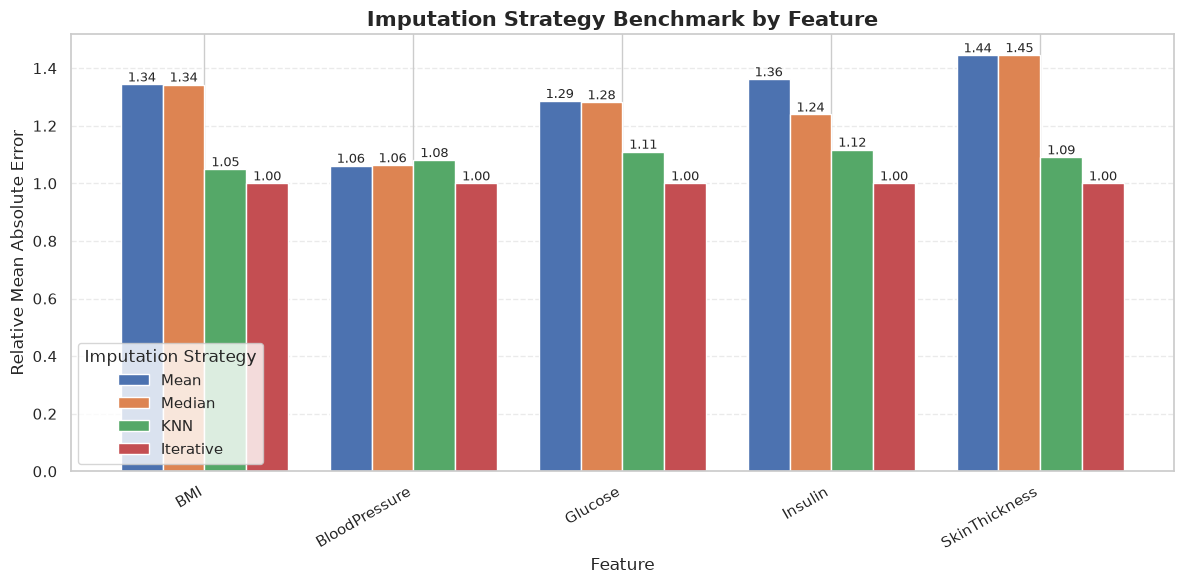

In [75]:
import matplotlib.pyplot as plt
import numpy as np

plot_data = imputation_benchmark.pivot(
    index="feature",
    columns="method",
    values="relative_mae"
)

strategy_order = ["Mean", "Median", "KNN", "Iterative"]

plot_data = plot_data[
    [strategy for strategy in strategy_order if strategy in plot_data.columns]
]

x = np.arange(len(plot_data.index))
n_methods = len(plot_data.columns)

bar_width = 0.8 / n_methods

fig, ax = plt.subplots(figsize=(12, 6))

for i, method in enumerate(plot_data.columns):
    bars = ax.bar(
        x + i * bar_width,
        plot_data[method],
        width=bar_width,
        label=method
    )
    
    for bar in bars:
        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

ax.set_title(
    "Imputation Strategy Benchmark by Feature",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel(
    "Feature",
    fontsize=12
)

ax.set_ylabel(
    "Relative Mean Absolute Error",
    fontsize=12
)

ax.set_xticks(
    x + bar_width * (n_methods - 1) / 2
)

ax.set_xticklabels(
    plot_data.index,
    rotation=30,
    ha="right"
)

ax.legend(
    title="Imputation Strategy"
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

## 16. Performance des méthodes d'imputation par variable

Nous calculons la MAE moyenne et la NMAE moyenne pour chaque méthode et chaque variable.

La NMAE est particulièrement importante car les variables n'ont pas la même échelle.

In [81]:
imputation_by_feature = (
    imputation_benchmark
    .groupby(["feature", "method"])[
        ["mae", "relative_mae", "relative_mae_percent"]
    ]
    .mean()
    .reset_index()
)

display(imputation_by_feature)

,feature,method,mae,relative_mae,relative_mae_percent
0,BMI,Iterative,3.950728,1.000000,100.000000
1,BMI,KNN,4.144526,1.049054,104.905371
2,BMI,Mean,5.307978,1.343544,134.354445
3,BMI,Median,5.306923,1.343277,134.327731
4,BloodPressure,Iterative,9.714520,1.000000,100.000000
5,BloodPressure,KNN,10.500333,1.080891,108.089065
6,BloodPressure,Mean,10.309377,1.061234,106.123391
7,BloodPressure,Median,10.325641,1.062908,106.290805
8,Glucose,Iterative,19.068519,1.000000,100.000000
9,Glucose,KNN,21.165670,1.109980,110.997979


## 17. Sélection de la méthode d'imputation

La meilleure méthode sera déterminée séparément pour chaque variable selon la NMAE moyenne.

Cette approche est préférable à une décision basée uniquement sur une MAE globale, car :

- `Insulin` possède une échelle beaucoup plus grande ;
- `DiabetesPedigreeFunction` possède une échelle beaucoup plus petite ;
- les distributions et les taux de valeurs manquantes diffèrent fortement d'une variable à l'autre.

La méthode retenue est donc celle qui reconstruit le mieux chaque variable individuellement.

In [83]:
best_method_by_feature = (
    imputation_by_feature
    .loc[
        imputation_by_feature
        .groupby("feature")["relative_mae"]
        .idxmin()
    ]
    [["feature", "method", "mae", "relative_mae", "relative_mae_percent"]]
    .reset_index(drop=True)
)

display(best_method_by_feature)

,feature,method,mae,relative_mae,relative_mae_percent
0,BMI,Iterative,3.950728,1.0,100.0
1,BloodPressure,Iterative,9.714520,1.0,100.0
2,Glucose,Iterative,19.068519,1.0,100.0
3,Insulin,Iterative,57.094527,1.0,100.0
4,SkinThickness,Iterative,6.099520,1.0,100.0


## 18. Comparaison globale

Nous calculons également la NMAE moyenne sur toutes les variables afin d'obtenir une mesure globale ne favorisant pas artificiellement les variables ayant de grandes unités.

In [85]:
global_imputation_results = (
    imputation_by_feature
    .groupby("method")["relative_mae"]
    .mean()
    .sort_values()
    .to_frame("mean_relative_mae")
)

display(global_imputation_results)

,mean_relative_mae
method,
Iterative,1.000000
KNN,1.089515
Median,1.274442
Mean,1.299405


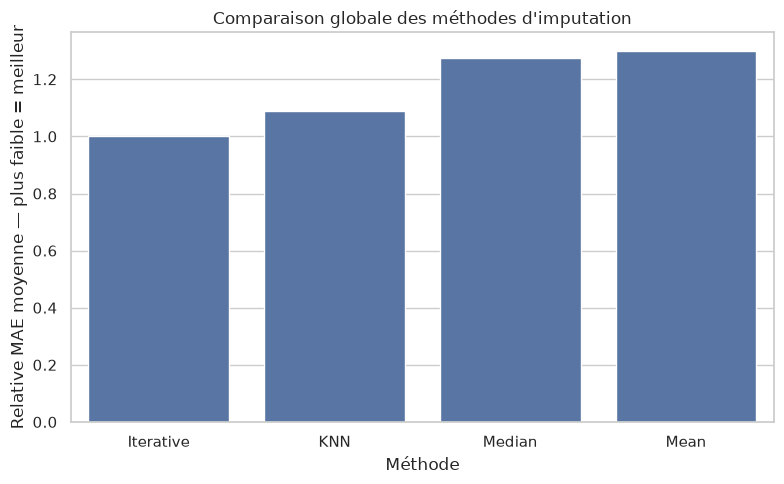

In [88]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=global_imputation_results.reset_index(),
    x="method",
    y="mean_relative_mae"
)

plt.title(
    "Comparaison globale des méthodes d'imputation"
)

plt.xlabel("Méthode")
plt.ylabel("Relative MAE moyenne — plus faible = meilleur")

plt.tight_layout()
plt.show()

## 19. Application de l'imputation finale

Nous appliquons maintenant les méthodes retenues.

Deux versions complètes du dataset sont calculées :

1. une version entièrement imputée par la médiane ;
2. une version entièrement imputée par KNN.

Ensuite, pour chaque variable, nous récupérons la méthode ayant obtenu la meilleure NMAE lors du benchmark.

Cette stratégie permet d'obtenir un dataset final adapté aux caractéristiques de chaque variable.

## 16. Boxplots et détection visuelle des valeurs extrêmes

Les boxplots permettent d'observer les valeurs situées loin de la zone centrale de chaque distribution.

Une observation située au-delà des moustaches n'est pas automatiquement une erreur.
Dans les données biomédicales, elle peut correspondre à un patient présentant réellement une caractéristique extrême.

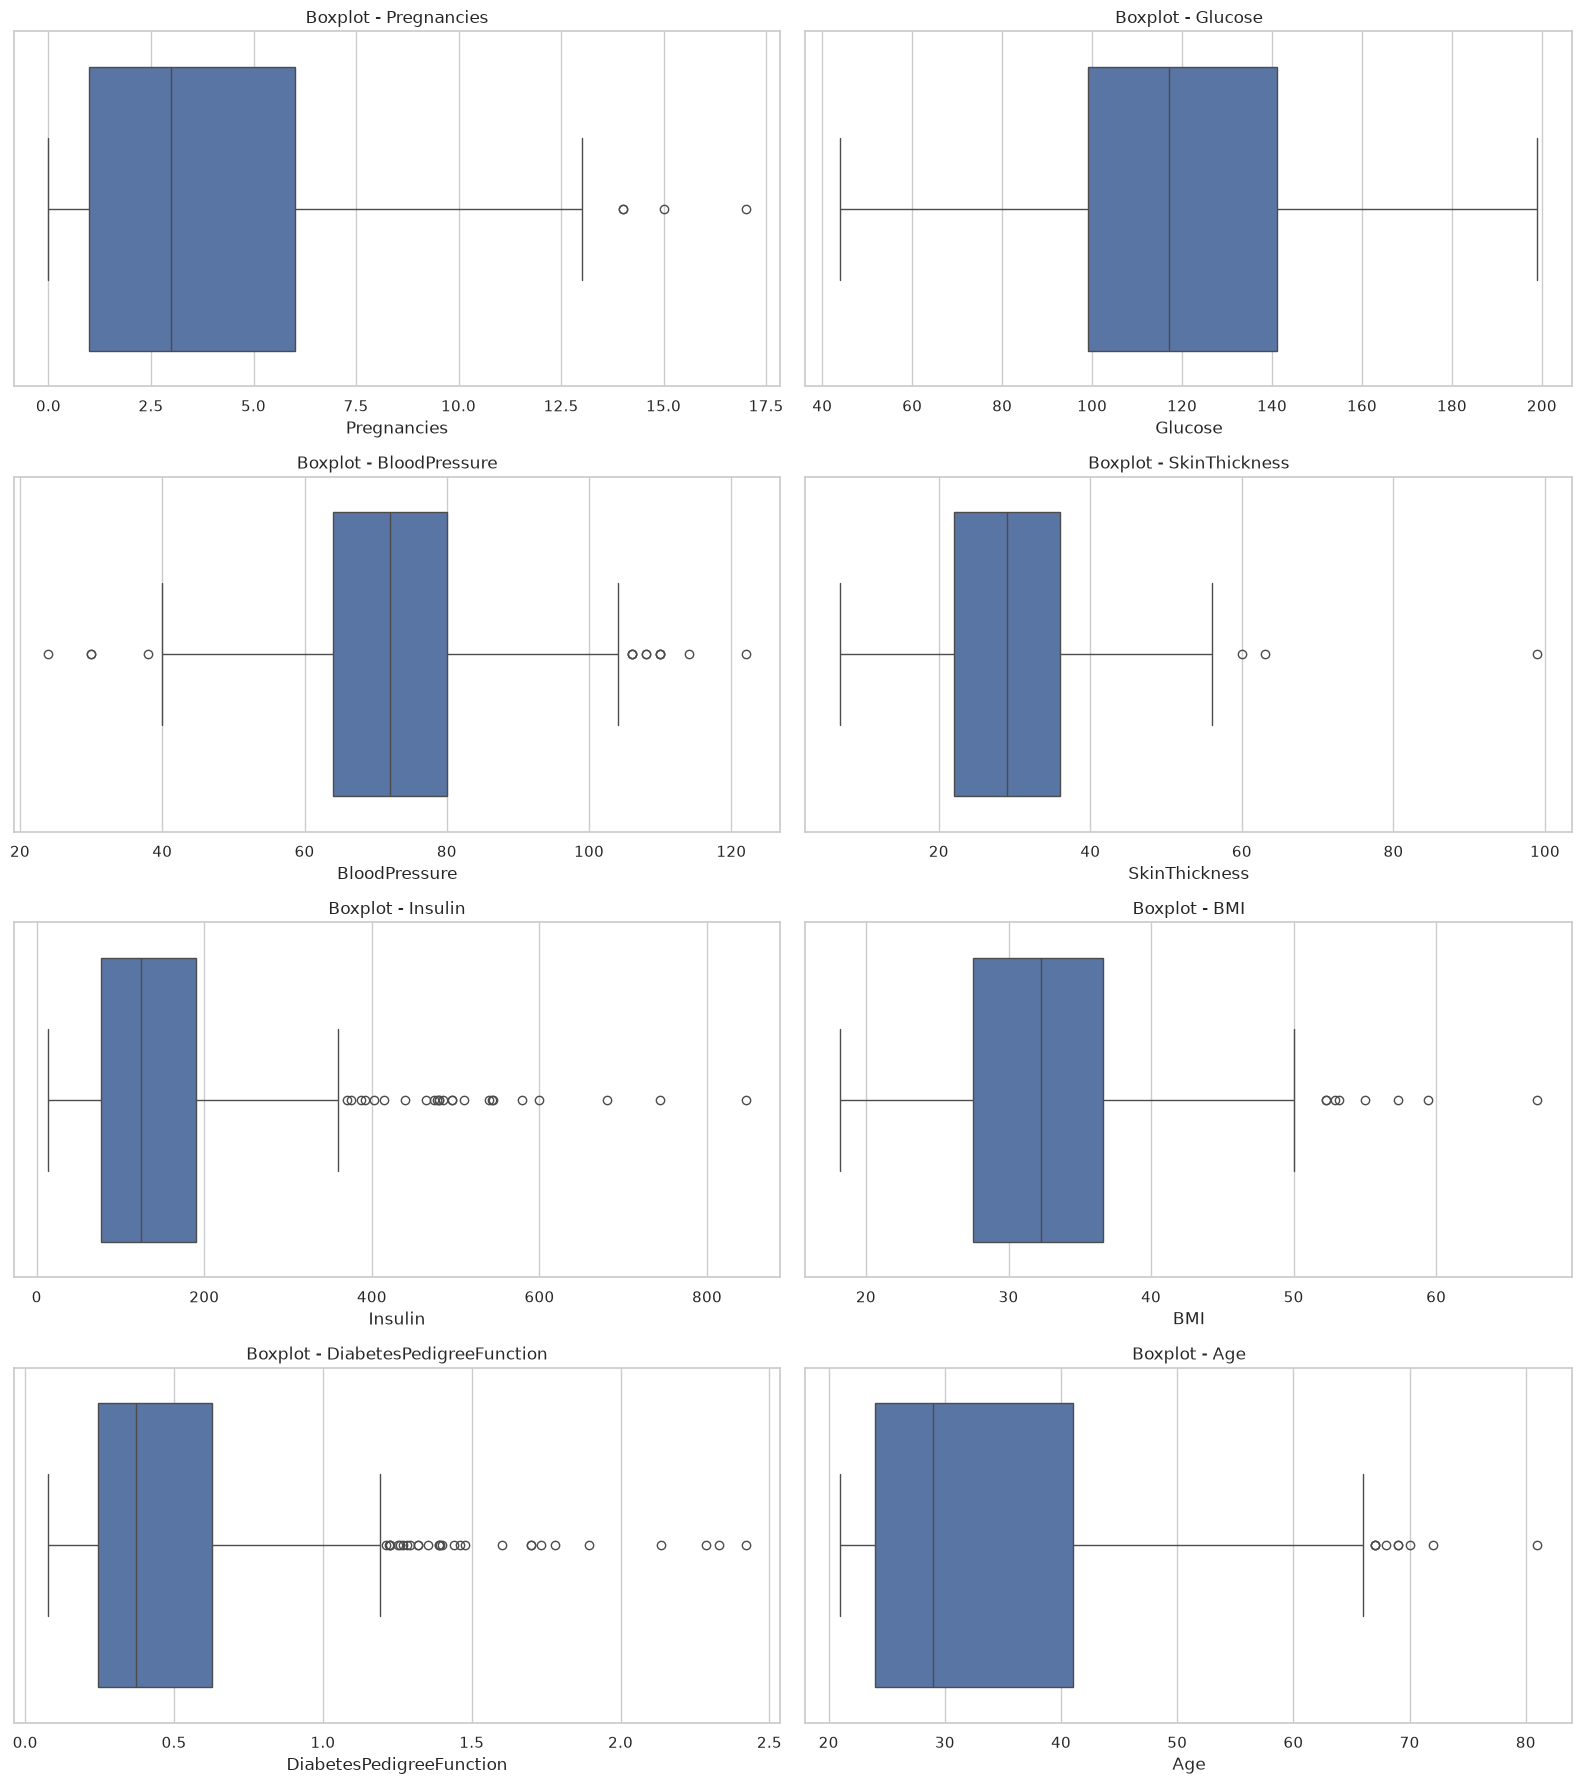

In [22]:
fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(16, 18)
)

axes = axes.flatten()

for ax, column in zip(axes, EXPECTED_FEATURES):
    sns.boxplot(
        x=df_clean[column],
        ax=ax
    )
    ax.set_title(f"Boxplot - {column}")
    ax.set_xlabel(column)

plt.tight_layout()
plt.show()

## 17. Détection des outliers avec la méthode IQR

Pour chaque variable numérique :

- Q1 = premier quartile ;
- Q3 = troisième quartile ;
- IQR = Q3 - Q1.

Les bornes sont définies par :

Upper Bound = Q3 + 1.5 × IQR

Lower Bound = Q1 - 1.5 × IQR

Une observation en dehors de ces bornes est considérée comme un outlier statistique.

Cette méthode sera utilisée pour **détecter et documenter** les observations extrêmes.

In [23]:
outlier_summary = []

for column in EXPECTED_FEATURES:
    series = df_clean[column].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (df_clean[column] < lower_bound)
        | (df_clean[column] > upper_bound)
    )

    outlier_count = outlier_mask.sum()

    outlier_summary.append({
        "feature": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outlier_count,
        "outlier_percentage": (
            outlier_count / len(df_clean) * 100
        ),
    })

outlier_report = pd.DataFrame(outlier_summary)

display(
    outlier_report.sort_values(
        by="outlier_percentage",
        ascending=False
    )
)

,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
6,DiabetesPedigreeFunction,0.24375,0.62625,0.3825,-0.330,1.200,29,3.776042
4,Insulin,76.25000,190.00000,113.7500,-94.375,360.625,24,3.125000
2,BloodPressure,64.00000,80.00000,16.0000,40.000,104.000,14,1.822917
7,Age,24.00000,41.00000,17.0000,-1.500,66.500,9,1.171875
5,BMI,27.50000,36.60000,9.1000,13.850,50.250,8,1.041667
0,Pregnancies,1.00000,6.00000,5.0000,-6.500,13.500,4,0.520833
3,SkinThickness,22.00000,36.00000,14.0000,1.000,57.000,3,0.390625
1,Glucose,99.00000,141.00000,42.0000,36.000,204.000,0,0.000000


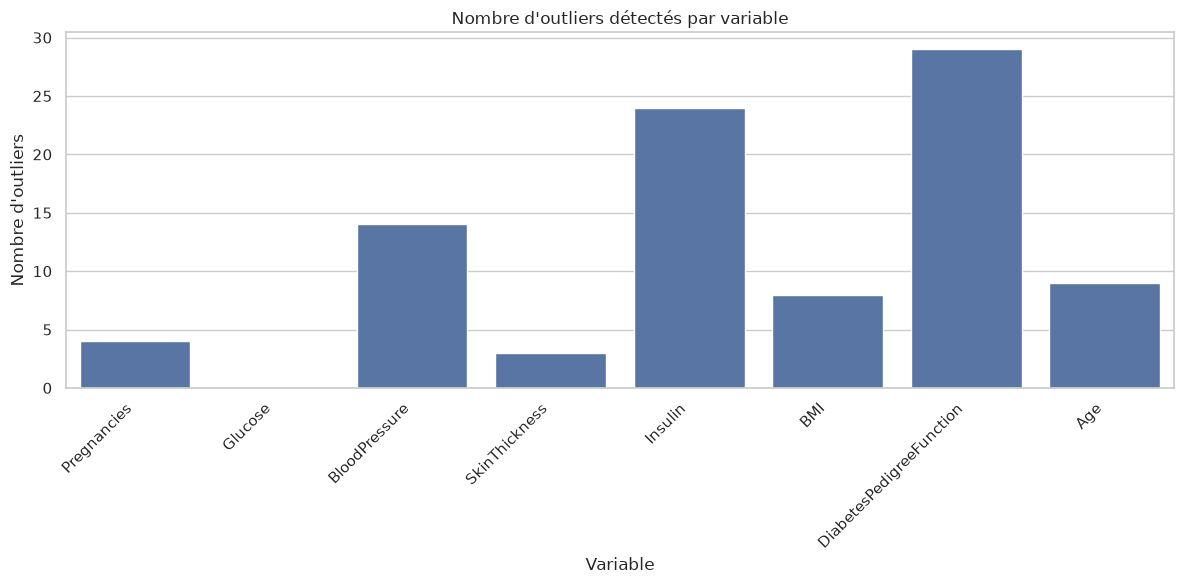

In [24]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=outlier_report,
    x="feature",
    y="outlier_count"
)

plt.xticks(rotation=45, ha="right")
plt.title("Nombre d'outliers détectés par variable")
plt.xlabel("Variable")
plt.ylabel("Nombre d'outliers")

plt.tight_layout()
plt.show()

## 18. Stratégie de gestion des outliers

La méthode IQR détecte des **outliers statistiques**, mais elle ne permet pas de conclure qu'une observation est incorrecte.

Dans un contexte biomédical, des valeurs élevées de Glucose, Insulin, BMI ou DiabetesPedigreeFunction peuvent représenter de véritables profils patients.

Supprimer automatiquement ces lignes pourrait :

- supprimer des cas cliniquement intéressants ;
- réduire la diversité du dataset ;
- modifier artificiellement la structure des groupes ;
- biaiser le clustering ;
- supprimer précisément les profils à risque que le projet cherche à identifier.

### Décision

Nous allons donc :

1. détecter les outliers avec IQR ;
2. les documenter ;
3. ne pas supprimer automatiquement les lignes ;
4. ne pas appliquer de clipping arbitraire ;
5. utiliser ultérieurement un **RobustScaler** pour réduire leur influence lors du clustering.

Cette stratégie permet de conserver l'information clinique tout en limitant l'impact des valeurs extrêmes sur les algorithmes basés sur la distance.

## 19. Application de l'imputation finale

Les résultats du benchmark montrent que **IterativeImputer** obtient la meilleure performance pour toutes les variables présentant des valeurs manquantes :

| Variable | Meilleure méthode |
|---|---|
| BMI | Iterative |
| BloodPressure | Iterative |
| Glucose | Iterative |
| Insulin | Iterative |
| SkinThickness | Iterative |

La méthode itérative est donc retenue pour le dataset final.

### Pourquoi IterativeImputer ?

Contrairement à une imputation par moyenne ou médiane, l'imputation itérative utilise les relations entre les variables pour estimer progressivement les valeurs manquantes.

Cette propriété est particulièrement intéressante dans notre dataset car les variables cliniques présentent des relations entre elles.

Par exemple, une valeur manquante de `Insulin` peut être estimée à partir d'autres caractéristiques disponibles du même patient, telles que :

- Glucose ;
- BMI ;
- Age ;
- BloodPressure ;
- SkinThickness ;
- Pregnancies ;
- DiabetesPedigreeFunction.

### Configuration

Nous conservons la même configuration que celle utilisée pendant le benchmark afin de garantir la cohérence entre l'évaluation et l'imputation finale.

L'imputation est appliquée sur les huit variables numériques. Les variables qui ne contiennent aucune valeur manquante sont conservées telles quelles.

> Important :
> cette imputation produit un dataset complet destiné à l'analyse exploratoire et au clustering.
> Lors de la future classification supervisée, les transformations de preprocessing devront être intégrées dans un Pipeline et ajustées uniquement sur les données d'entraînement afin d'éviter toute fuite de données.

In [89]:
FINAL_IMPUTER = IterativeImputer(
    random_state=42
)

df_before_imputation = df_clean.copy()

imputed_values = FINAL_IMPUTER.fit_transform(
    df_clean[EXPECTED_FEATURES]
)

df_clean = pd.DataFrame(
    imputed_values,
    columns=EXPECTED_FEATURES,
    index=df_clean.index
)

print("✅ Imputation itérative terminée.")

✅ Imputation itérative terminée.


## 20. Vérification après imputation

Après l'application de `IterativeImputer`, nous vérifions qu'aucune valeur manquante ne subsiste.

Nous vérifions également :

- les dimensions ;
- les types ;
- les valeurs infinies ;
- les statistiques générales.

Le dataset doit maintenant être complètement renseigné.

In [90]:
print("Dimensions :", df_clean.shape)

print(
    "\nNombre total de NaN :",
    df_clean.isna().sum().sum()
)

print(
    "\nNombre total de valeurs infinies :",
    np.isinf(df_clean.to_numpy()).sum()
)

print("\nTypes :")
print(df_clean.dtypes)

Dimensions : (768, 8)

Nombre total de NaN : 0

Nombre total de valeurs infinies : 0

Types :
Pregnancies                 float64
Glucose                     float64
BloodPressure               float64
SkinThickness               float64
Insulin                     float64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                         float64
dtype: object


In [91]:
assert df_clean.isna().sum().sum() == 0

assert np.isfinite(
    df_clean.to_numpy()
).all()

print(
    "✅ Aucune valeur manquante ou infinie restante."
)

✅ Aucune valeur manquante ou infinie restante.


## 21. Comparaison des distributions avant et après imputation

Nous comparons les distributions des variables incomplètes avant et après l'imputation.

L'objectif est de vérifier que l'imputation :

- conserve globalement la forme des distributions ;
- n'introduit pas de valeurs manifestement aberrantes ;
- ne crée pas une concentration artificielle excessive autour d'une valeur unique.

Cette comparaison est particulièrement importante pour `Insulin` et `SkinThickness`, qui possèdent les taux de valeurs manquantes les plus élevés.

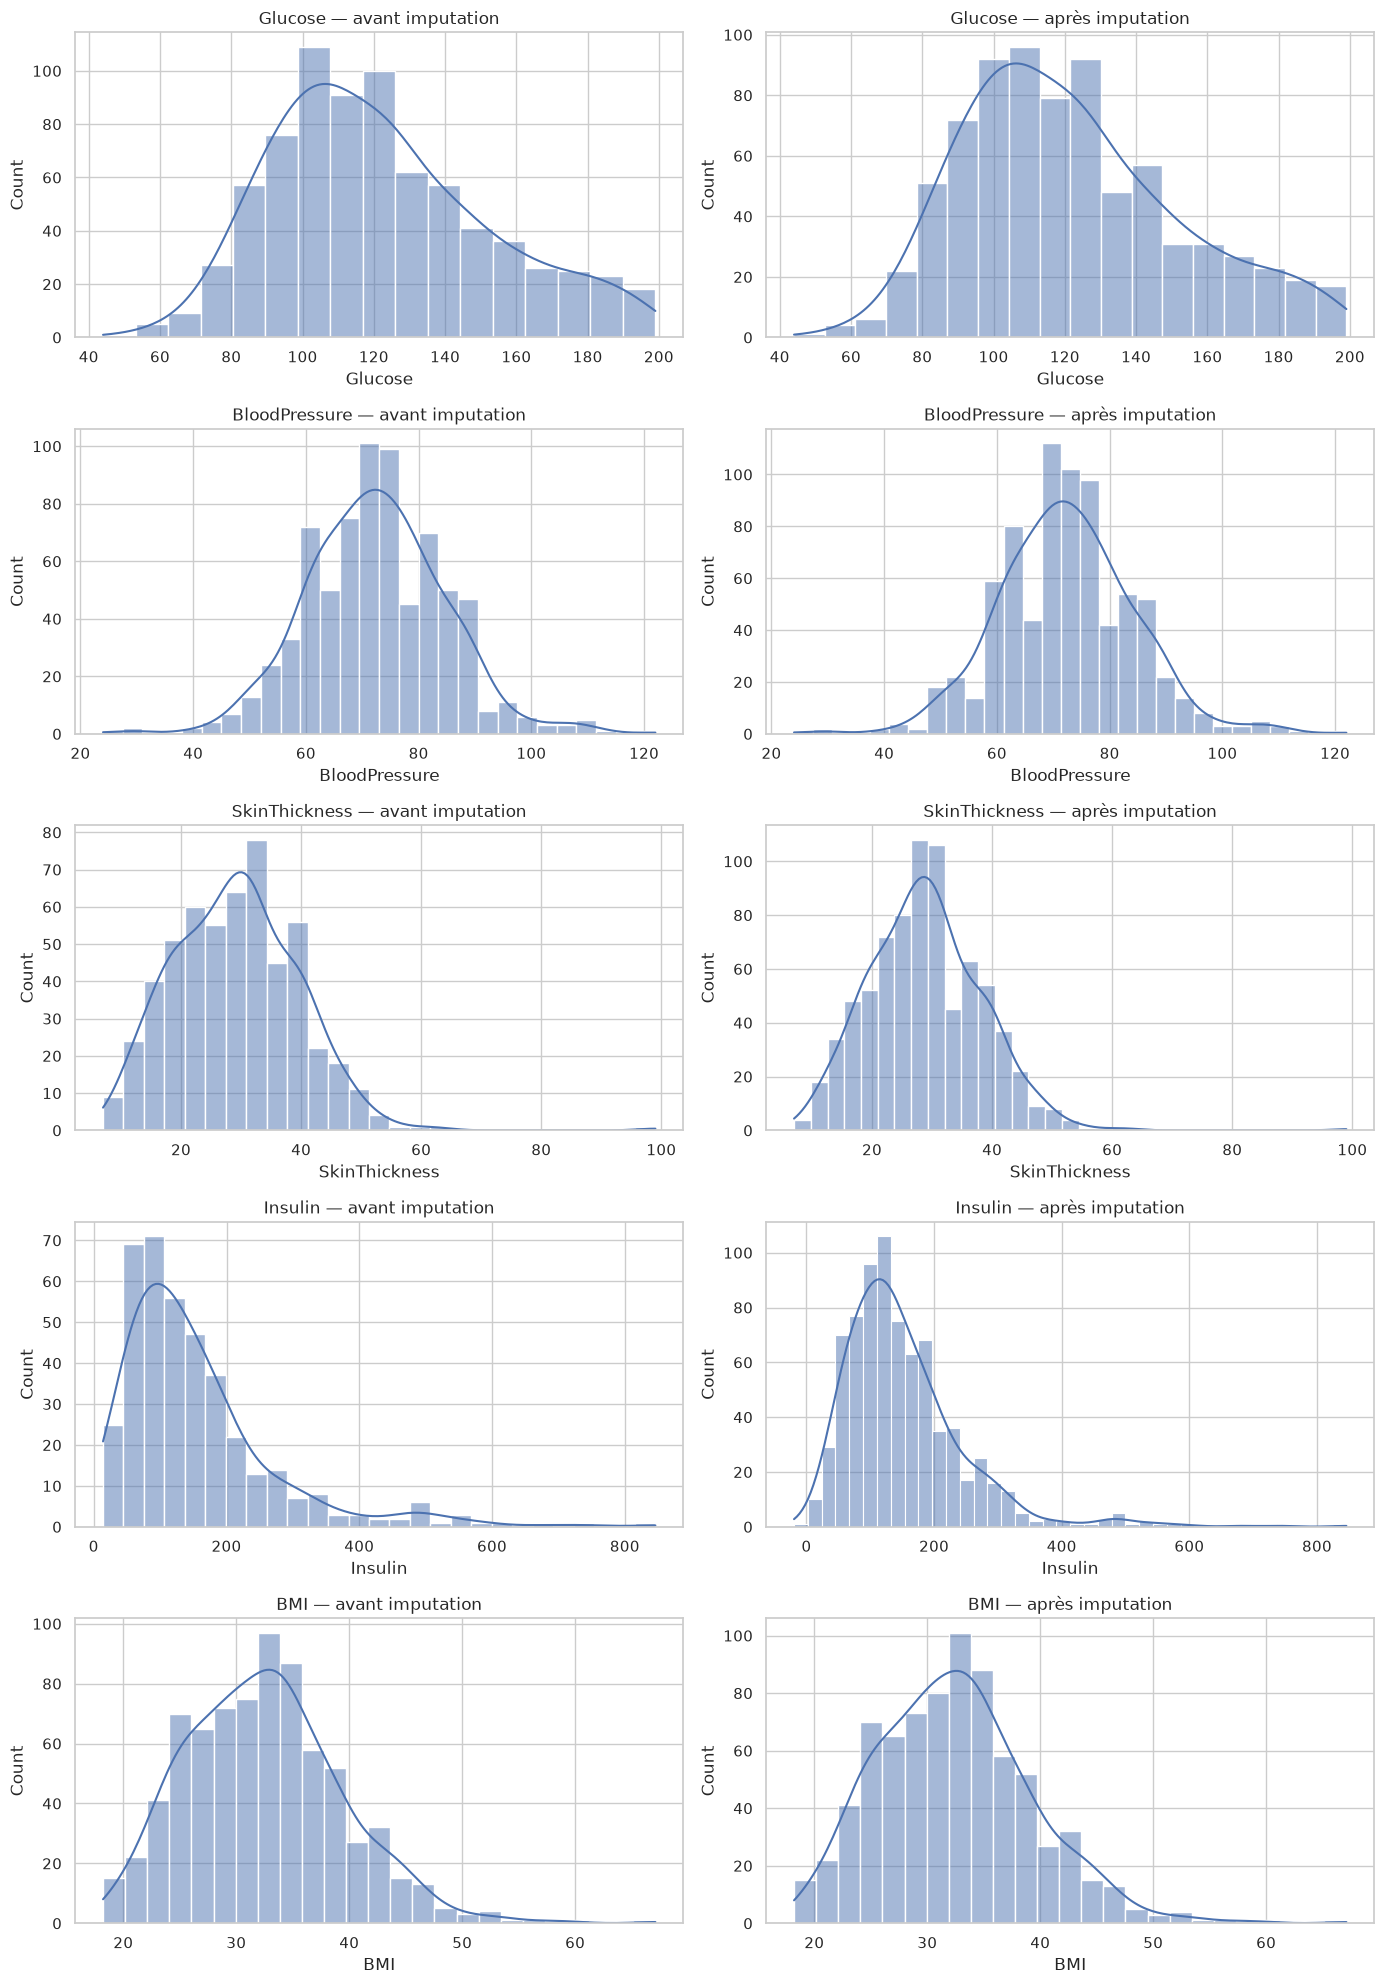

In [92]:
FEATURES_WITH_MISSING = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
]

fig, axes = plt.subplots(
    nrows=len(FEATURES_WITH_MISSING),
    ncols=2,
    figsize=(14, 20)
)

for i, column in enumerate(FEATURES_WITH_MISSING):

    sns.histplot(
        df_before_imputation[column],
        kde=True,
        ax=axes[i, 0]
    )

    axes[i, 0].set_title(
        f"{column} — avant imputation"
    )

    sns.histplot(
        df_clean[column],
        kde=True,
        ax=axes[i, 1]
    )

    axes[i, 1].set_title(
        f"{column} — après imputation"
    )

plt.tight_layout()
plt.show()

## 22. Vérification des valeurs imputées

Nous identifions les observations qui ont reçu une valeur imputée.

Cette information nous permet de vérifier :

- le nombre de valeurs nouvellement estimées ;
- les statistiques des valeurs imputées ;
- leur cohérence avec les valeurs observées.

Les valeurs imputées ne sont pas considérées comme des mesures originales : elles sont des estimations statistiques.

In [93]:
imputed_mask = (
    df_before_imputation[EXPECTED_FEATURES]
    .isna()
)

imputation_summary = pd.DataFrame({
    "original_missing": imputed_mask.sum(),
    "final_missing": df_clean.isna().sum(),
})

display(imputation_summary)

,original_missing,final_missing
Pregnancies,0,0
Glucose,5,0
BloodPressure,35,0
SkinThickness,227,0
Insulin,374,0
BMI,11,0
DiabetesPedigreeFunction,0,0
Age,0,0


In [94]:
imputed_values_report = []

for column in FEATURES_WITH_MISSING:

    mask = imputed_mask[column]

    imputed_series = df_clean.loc[
        mask,
        column
    ]

    imputed_values_report.append({
        "feature": column,
        "imputed_count": len(imputed_series),
        "imputed_mean": imputed_series.mean(),
        "imputed_median": imputed_series.median(),
        "imputed_min": imputed_series.min(),
        "imputed_max": imputed_series.max(),
    })

imputed_values_report = pd.DataFrame(
    imputed_values_report
)

display(imputed_values_report)

,feature,imputed_count,imputed_mean,imputed_median,imputed_min,imputed_max
0,Glucose,5,114.802213,116.515318,91.593597,131.495099
1,BloodPressure,35,71.248067,70.188097,62.665256,84.534822
2,SkinThickness,227,28.319352,27.686038,14.031305,48.996624
3,Insulin,374,149.597464,136.922898,-19.507362,349.658777
4,BMI,11,31.453533,31.010189,29.646522,34.861257


## 23. Analyse des distributions après nettoyage

Le dataset étant maintenant complet, nous analysons les distributions finales.

Cette étape permet d'observer :

- la tendance centrale ;
- la dispersion ;
- l'asymétrie ;
- les valeurs extrêmes potentielles.

Ces observations serviront directement à l'étape de détection des outliers.

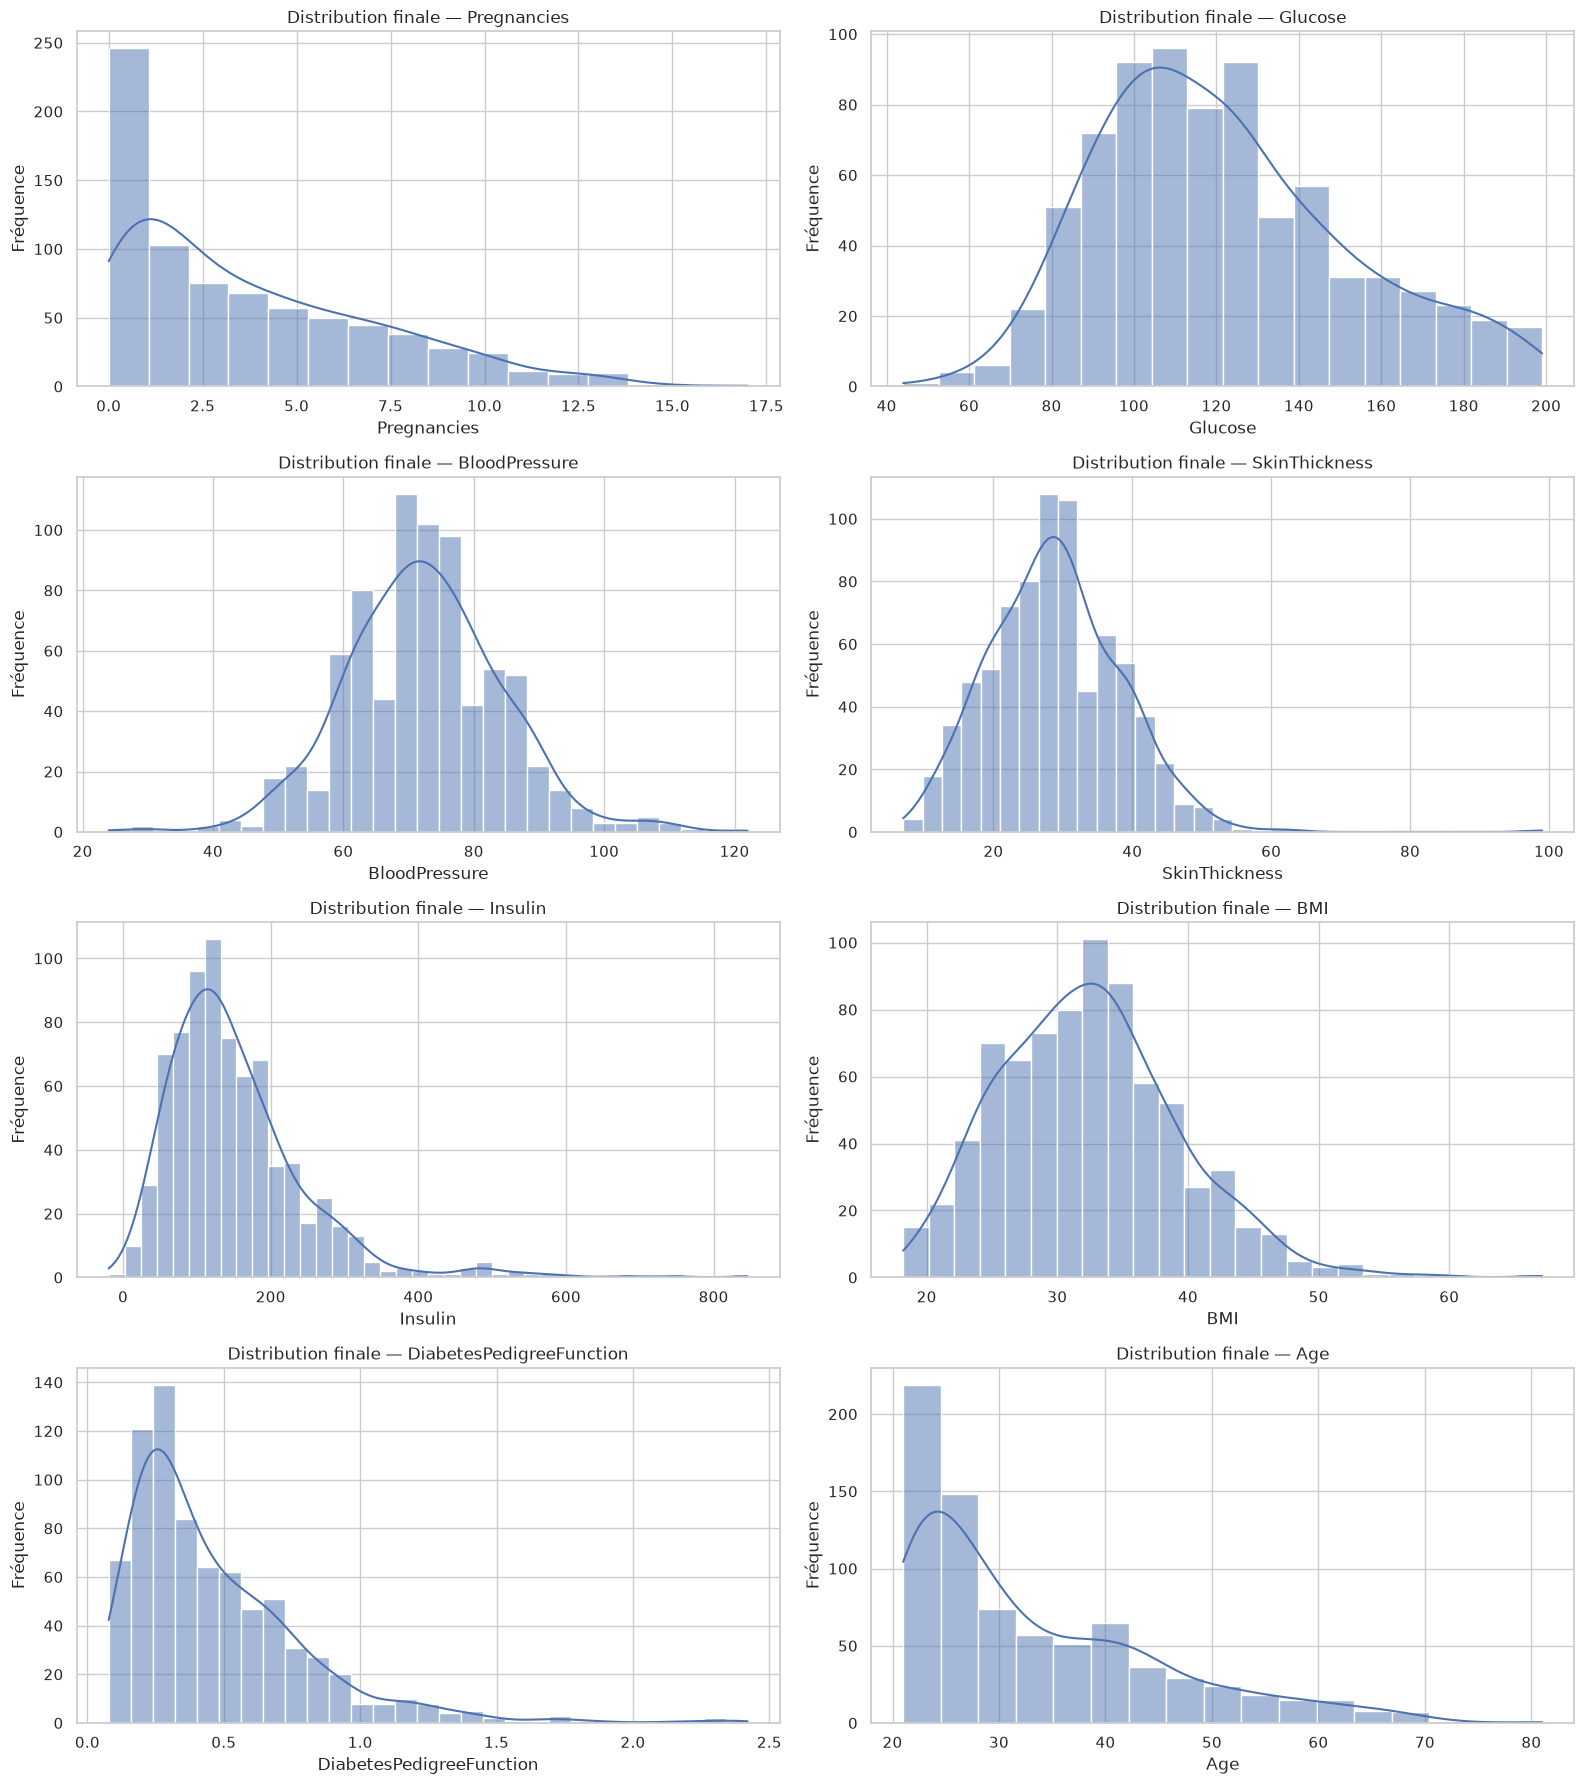

In [95]:
fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(16, 18)
)

axes = axes.flatten()

for ax, column in zip(
    axes,
    EXPECTED_FEATURES
):

    sns.histplot(
        df_clean[column],
        kde=True,
        ax=ax
    )

    ax.set_title(
        f"Distribution finale — {column}"
    )

    ax.set_xlabel(column)
    ax.set_ylabel("Fréquence")

plt.tight_layout()
plt.show()

## 24. Boxplots après imputation

Les boxplots sont recalculés après l'imputation.

Il s'agit maintenant du dataset qui sera soumis à la détection finale des outliers.

Les valeurs situées au-delà des moustaches seront considérées comme des outliers statistiques selon la règle IQR.

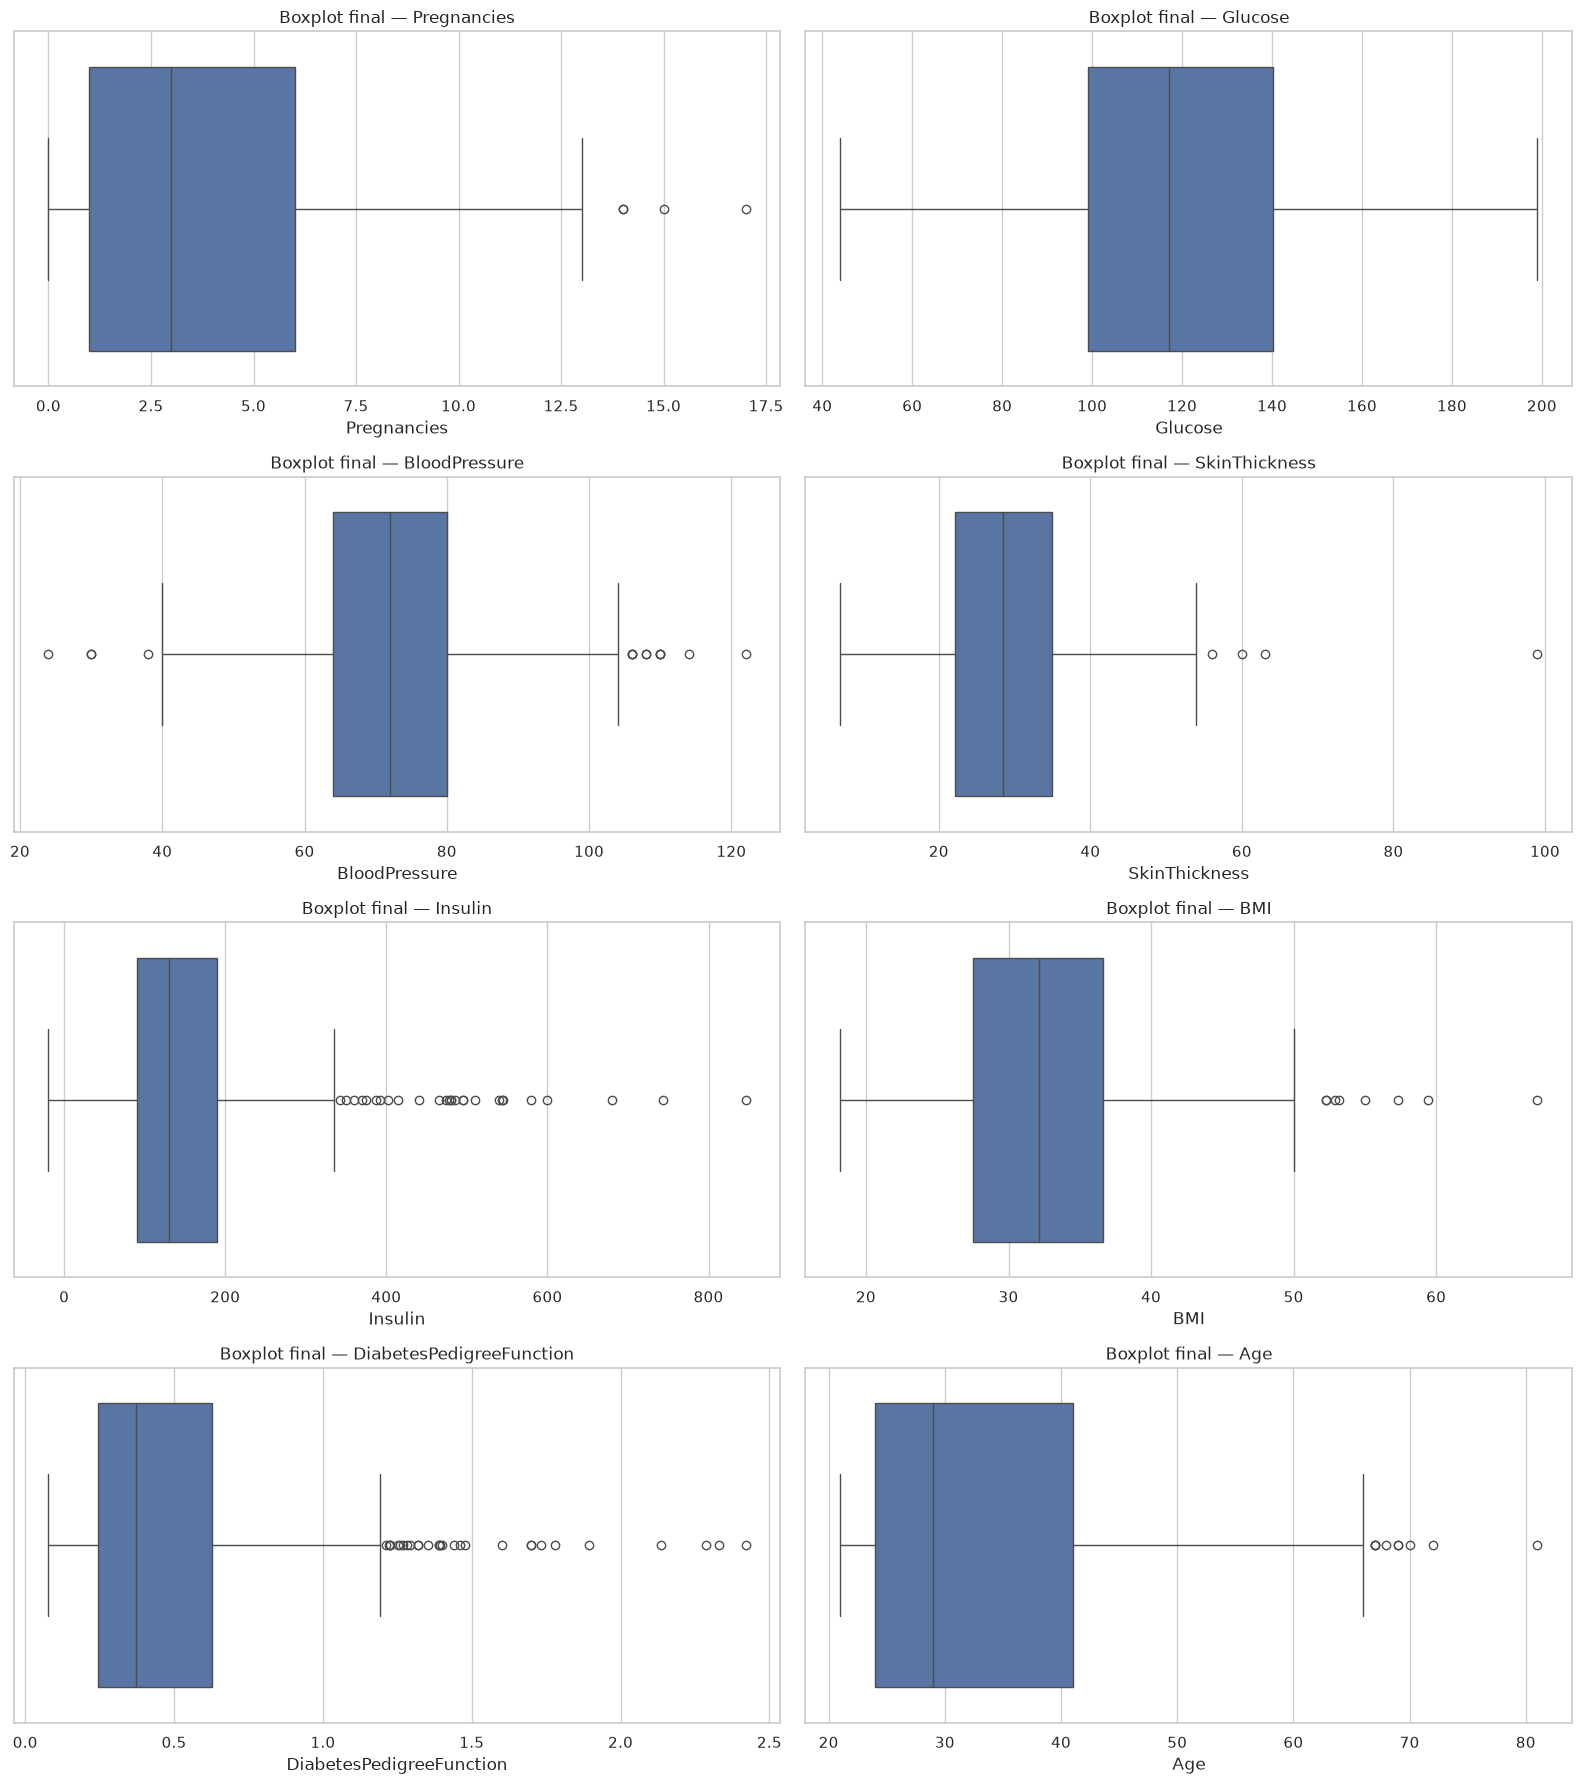

In [96]:
fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(16, 18)
)

axes = axes.flatten()

for ax, column in zip(
    axes,
    EXPECTED_FEATURES
):

    sns.boxplot(
        x=df_clean[column],
        ax=ax
    )

    ax.set_title(
        f"Boxplot final — {column}"
    )

    ax.set_xlabel(column)

plt.tight_layout()
plt.show()

## 25. Validation des valeurs imputées

Avant de commencer l'analyse des outliers, nous devons vérifier que l'imputation n'a pas généré de valeurs incompatibles avec la définition des variables.

L'imputation est une estimation statistique : elle doit donc rester dans un domaine cohérent avec les valeurs observées.

Nous vérifions notamment que :

- `Pregnancies >= 0`
- `Glucose > 0`
- `BloodPressure > 0`
- `SkinThickness > 0`
- `Insulin > 0`
- `BMI > 0`
- `DiabetesPedigreeFunction >= 0`
- `Age > 0`

Les limites inférieure et supérieure seront calculées à partir des valeurs observées avant imputation.

Cette stratégie permet d'éviter qu'une valeur imputée soit statistiquement plausible pour le modèle d'imputation mais impossible pour la variable clinique.

In [97]:
observed_lower_bounds = (
    df_before_imputation[EXPECTED_FEATURES]
    .min()
)

observed_upper_bounds = (
    df_before_imputation[EXPECTED_FEATURES]
    .max()
)

bounds_report = pd.DataFrame({
    "observed_min": observed_lower_bounds,
    "observed_max": observed_upper_bounds,
})

display(bounds_report)

,observed_min,observed_max
Pregnancies,0.000,17.00
Glucose,44.000,199.00
BloodPressure,24.000,122.00
SkinThickness,7.000,99.00
Insulin,14.000,846.00
BMI,18.200,67.10
DiabetesPedigreeFunction,0.078,2.42
Age,21.000,81.00


In [98]:
current_validity_report = pd.DataFrame({
    "min": df_clean.min(),
    "max": df_clean.max(),
})

display(current_validity_report)

,min,max
Pregnancies,0.000000,17.00
Glucose,44.000000,199.00
BloodPressure,24.000000,122.00
SkinThickness,7.000000,99.00
Insulin,-19.507362,846.00
BMI,18.200000,67.10
DiabetesPedigreeFunction,0.078000,2.42
Age,21.000000,81.00


## 26. Imputation contrainte

Si une valeur imputée sort du domaine observé de sa variable, nous réappliquons `IterativeImputer` avec des bornes.

Cette opération ne change pas la méthode d'imputation choisie.

La décision reste :

> **IterativeImputer**

Nous ajoutons simplement des contraintes afin d'éviter des estimations physiologiquement incohérentes.

Les bornes sont dérivées des valeurs réellement observées avant l'imputation.

In [99]:
invalid_after_imputation = {
    "Pregnancies": (
        (df_clean["Pregnancies"] < 0)
    ).sum(),

    "Glucose": (
        (df_clean["Glucose"] <= 0)
    ).sum(),

    "BloodPressure": (
        (df_clean["BloodPressure"] <= 0)
    ).sum(),

    "SkinThickness": (
        (df_clean["SkinThickness"] <= 0)
    ).sum(),

    "Insulin": (
        (df_clean["Insulin"] <= 0)
    ).sum(),

    "BMI": (
        (df_clean["BMI"] <= 0)
    ).sum(),

    "DiabetesPedigreeFunction": (
        (df_clean["DiabetesPedigreeFunction"] < 0)
    ).sum(),

    "Age": (
        (df_clean["Age"] <= 0)
    ).sum(),
}

display(
    pd.DataFrame.from_dict(
        invalid_after_imputation,
        orient="index",
        columns=["invalid_count"]
    )
)

,invalid_count
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,1
BMI,0
DiabetesPedigreeFunction,0
Age,0


In [100]:
has_invalid_values = any(
    value > 0
    for value in invalid_after_imputation.values()
)

if has_invalid_values:

    lower_bounds = np.array([
        observed_lower_bounds[column]
        for column in EXPECTED_FEATURES
    ])

    upper_bounds = np.array([
        observed_upper_bounds[column]
        for column in EXPECTED_FEATURES
    ])

    FINAL_IMPUTER = IterativeImputer(
        random_state=42,
        min_value=lower_bounds,
        max_value=upper_bounds
    )

    imputed_values = FINAL_IMPUTER.fit_transform(
        df_before_imputation[EXPECTED_FEATURES]
    )

    df_clean = pd.DataFrame(
        imputed_values,
        columns=EXPECTED_FEATURES,
        index=df_before_imputation.index
    )

    print(
        "✅ Imputation réappliquée avec des bornes."
    )

else:

    print(
        "✅ Toutes les valeurs imputées sont déjà valides."
    )

✅ Imputation réappliquée avec des bornes.


## 27. Contrôle après imputation contrainte

Nous vérifions une dernière fois :

- les valeurs manquantes ;
- les valeurs infinies ;
- les valeurs impossibles ;
- les dimensions.

Le dataset doit être entièrement valide avant l'analyse des outliers.

In [101]:
print(
    "NaN :",
    df_clean.isna().sum().sum()
)

print(
    "Infinités :",
    np.isinf(df_clean.to_numpy()).sum()
)

print(
    "Dimensions :",
    df_clean.shape
)

NaN : 0
Infinités : 0
Dimensions : (768, 8)


In [102]:
assert df_clean.isna().sum().sum() == 0

assert np.isfinite(
    df_clean.to_numpy()
).all()

assert (df_clean["Pregnancies"] >= 0).all()
assert (df_clean["Glucose"] > 0).all()
assert (df_clean["BloodPressure"] > 0).all()
assert (df_clean["SkinThickness"] > 0).all()
assert (df_clean["Insulin"] > 0).all()
assert (df_clean["BMI"] > 0).all()
assert (
    df_clean["DiabetesPedigreeFunction"] >= 0
).all()
assert (df_clean["Age"] > 0).all()

print(
    "✅ Dataset valide après imputation."
)

✅ Dataset valide après imputation.


## 28. Détection finale des outliers

Le dataset est maintenant complet et valide.

Nous pouvons effectuer la détection finale des outliers avec la méthode IQR.

Pour chaque variable :

$$
IQR = Q3 - Q1
$$

$$
LowerBound = Q1 - 1.5 \times IQR
$$

$$
UpperBound = Q3 + 1.5 \times IQR
$$

Une observation située en dehors des bornes est considérée comme un outlier statistique.

Cette étape ne signifie pas qu'une observation est incorrecte.

Elle permet uniquement d'identifier les observations situées dans les queues de la distribution.

In [103]:
outlier_records = []

for column in EXPECTED_FEATURES:

    q1 = df_clean[column].quantile(0.25)
    q3 = df_clean[column].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    mask = (
        (df_clean[column] < lower_bound)
        |
        (df_clean[column] > upper_bound)
    )

    outlier_records.append({
        "feature": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": int(mask.sum()),
        "outlier_percentage": (
            mask.mean() * 100
        ),
    })

outlier_report = pd.DataFrame(
    outlier_records
)

display(
    outlier_report.sort_values(
        "outlier_percentage",
        ascending=False
    )
)

,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
6,DiabetesPedigreeFunction,0.243750,0.62625,0.382500,-0.330000,1.200000,29,3.776042
4,Insulin,89.983915,190.00000,100.016085,-60.040212,340.024127,27,3.515625
2,BloodPressure,64.000000,80.00000,16.000000,40.000000,104.000000,14,1.822917
7,Age,24.000000,41.00000,17.000000,-1.500000,66.500000,9,1.171875
5,BMI,27.500000,36.60000,9.100000,13.850000,50.250000,8,1.041667
0,Pregnancies,1.000000,6.00000,5.000000,-6.500000,13.500000,4,0.520833
3,SkinThickness,22.120843,35.00000,12.879157,2.802107,54.318736,4,0.520833
1,Glucose,99.000000,140.25000,41.250000,37.125000,202.125000,0,0.000000


## 29. Visualisation des outliers par variable

Nous visualisons le nombre d'outliers détectés pour chaque variable.

Cette représentation permet d'identifier rapidement les distributions qui possèdent les queues les plus importantes.

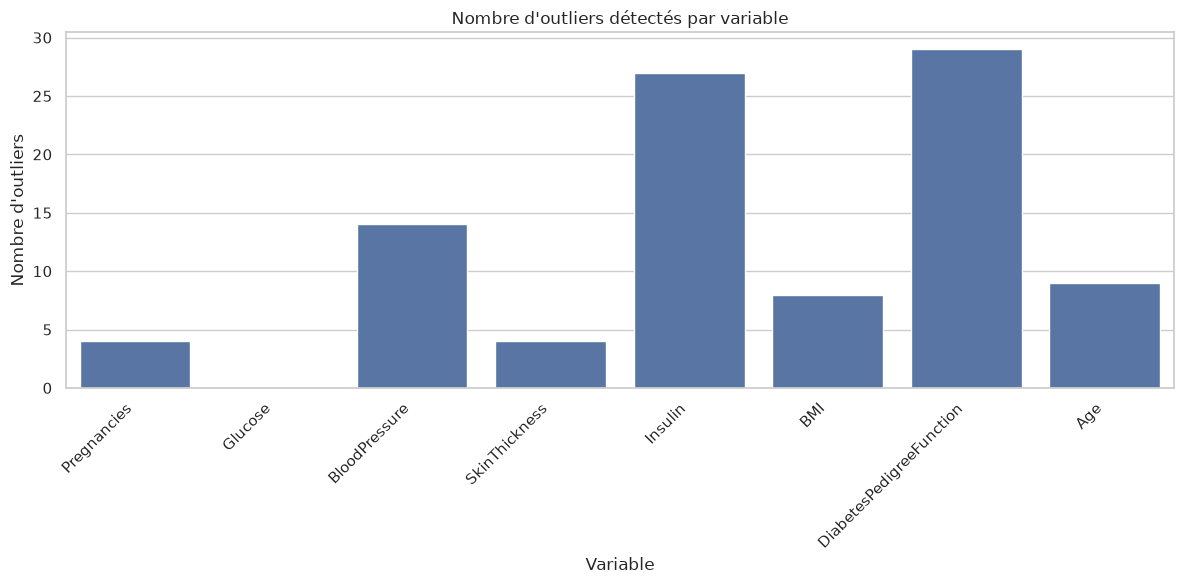

In [104]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=outlier_report,
    x="feature",
    y="outlier_count"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.title(
    "Nombre d'outliers détectés par variable"
)

plt.xlabel("Variable")
plt.ylabel("Nombre d'outliers")

plt.tight_layout()
plt.show()

## 30. Localisation des observations atypiques

Le nombre d'outliers ne suffit pas.

Nous voulons également voir où les observations atypiques se situent dans chaque distribution.

Les observations sont donc représentées individuellement afin d'identifier les valeurs extrêmes et leur distance par rapport au reste des données.

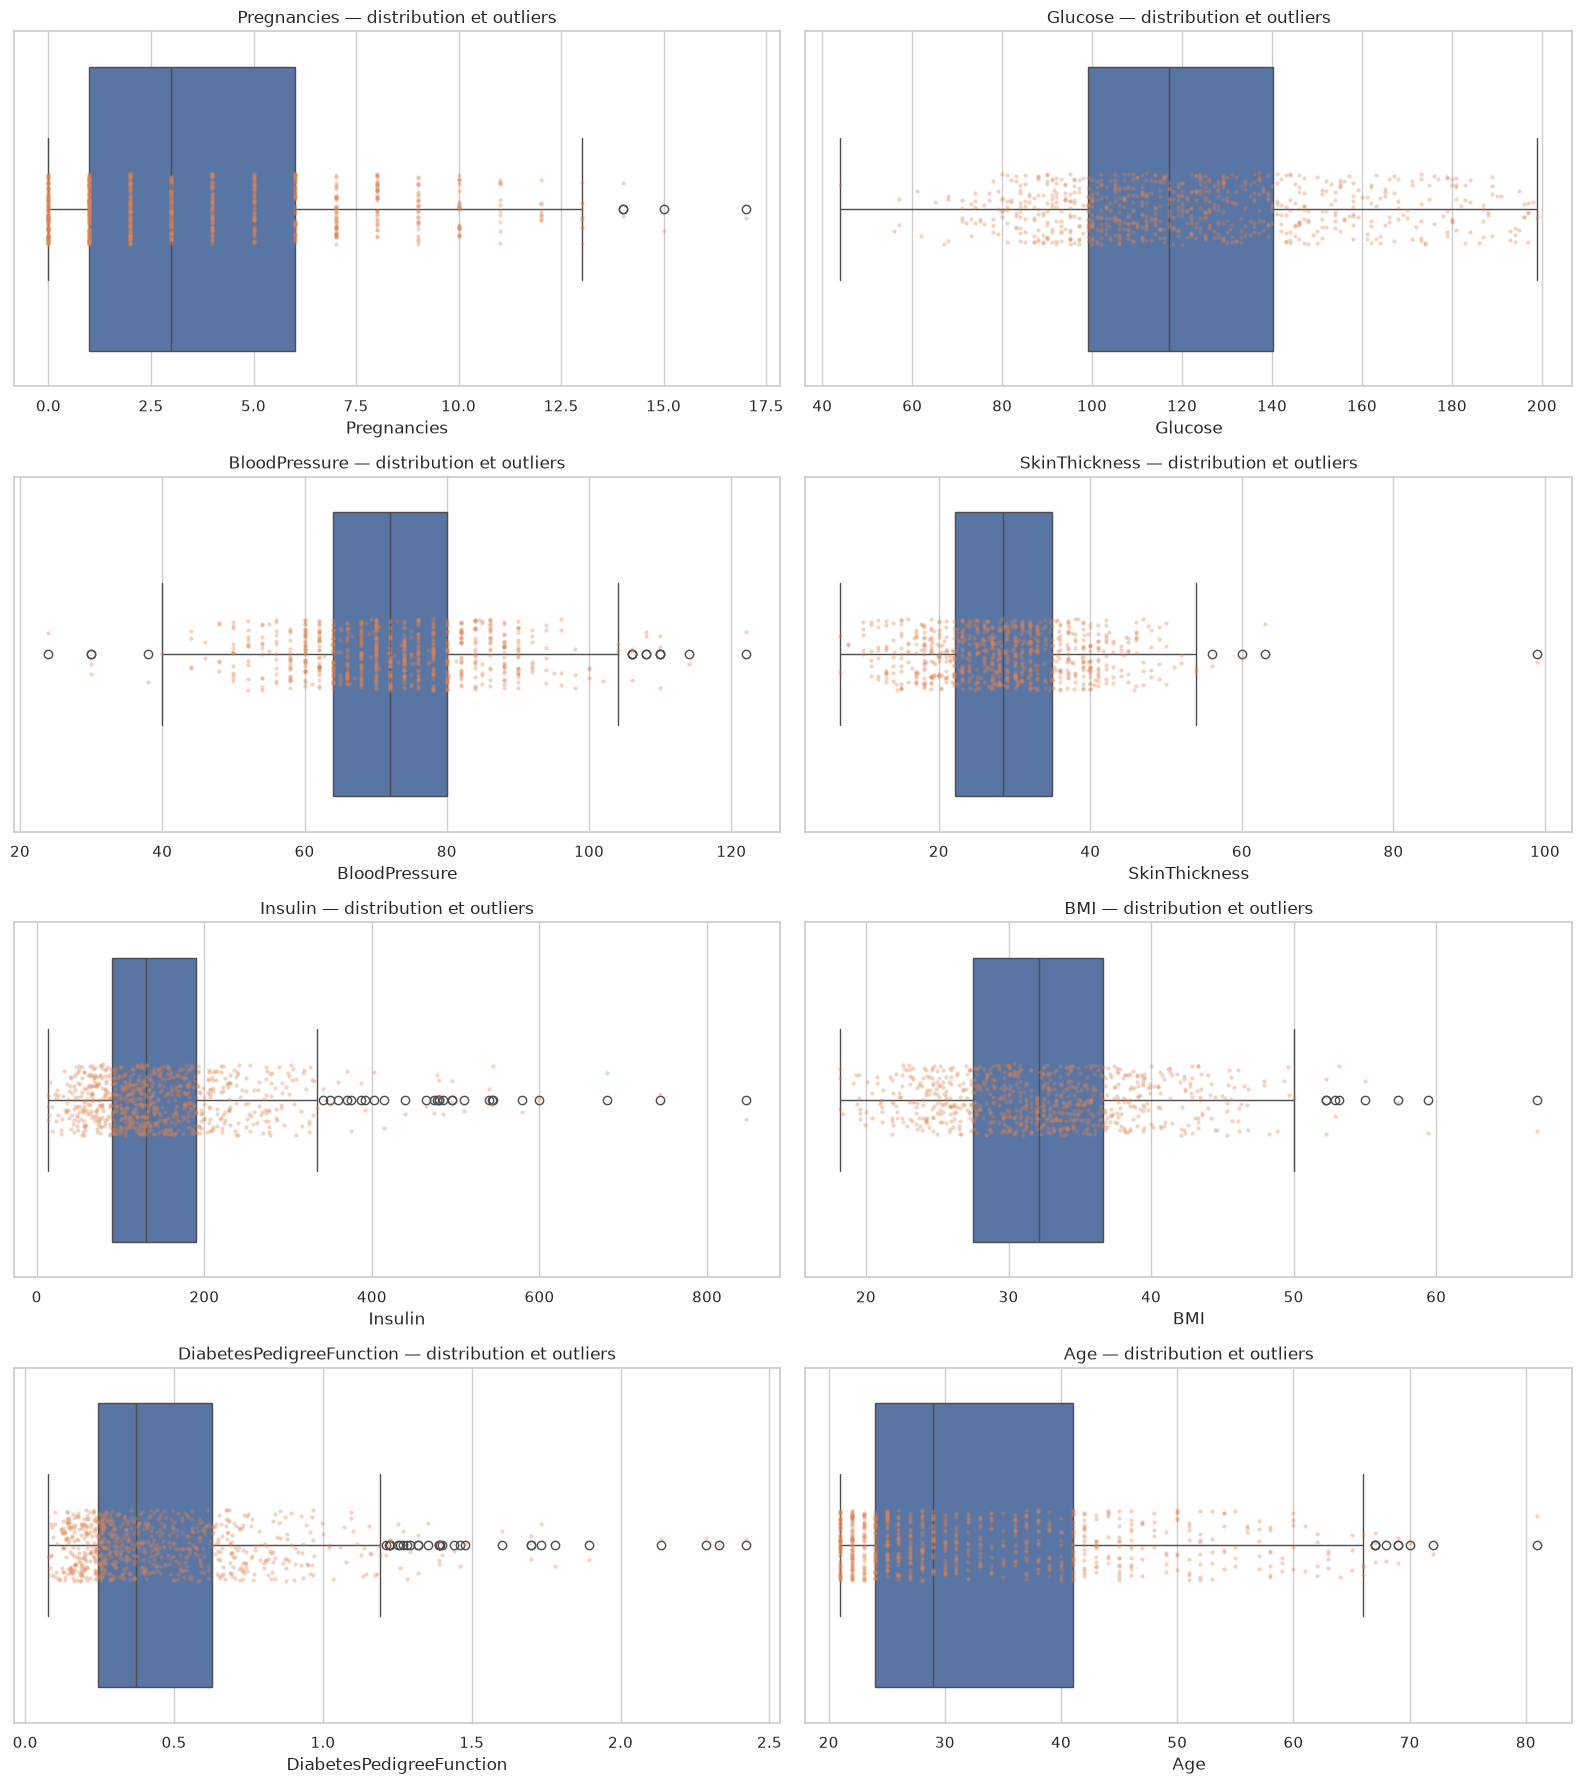

In [105]:
fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(16, 18)
)

axes = axes.flatten()

for ax, column in zip(
    axes,
    EXPECTED_FEATURES
):

    q1 = df_clean[column].quantile(0.25)
    q3 = df_clean[column].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    is_outlier = (
        (df_clean[column] < lower_bound)
        |
        (df_clean[column] > upper_bound)
    )

    sns.boxplot(
        x=df_clean[column],
        ax=ax
    )

    sns.stripplot(
        x=df_clean[column],
        ax=ax,
        size=3,
        alpha=0.35
    )

    ax.set_title(
        f"{column} — distribution et outliers"
    )

plt.tight_layout()
plt.show()

## 31. Identification des observations atypiques

Nous créons des indicateurs permettant de savoir quelles observations contiennent des valeurs extrêmes.

Ces indicateurs servent uniquement à l'analyse de qualité.

Ils ne seront pas utilisés comme features du modèle.

In [106]:
outlier_flags = pd.DataFrame(
    index=df_clean.index
)

for column in EXPECTED_FEATURES:

    q1 = df_clean[column].quantile(0.25)
    q3 = df_clean[column].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_flags[
        f"{column}_outlier"
    ] = (
        (df_clean[column] < lower_bound)
        |
        (df_clean[column] > upper_bound)
    )

outlier_flags["outlier_count"] = (
    outlier_flags.sum(axis=1)
)

outlier_flags["any_outlier"] = (
    outlier_flags["outlier_count"] > 0
)

display(
    outlier_flags.head()
)

,Pregnancies_outlier,Glucose_outlier,BloodPressure_outlier,SkinThickness_outlier,Insulin_outlier,BMI_outlier,DiabetesPedigreeFunction_outlier,Age_outlier,outlier_count,any_outlier
0,False,False,False,False,False,False,False,False,0,False
1,False,False,False,False,False,False,False,False,0,False
2,False,False,False,False,False,False,False,False,0,False
3,False,False,False,False,False,False,False,False,0,False
4,False,False,False,False,False,False,True,False,1,True


## 32. Analyse de l'asymétrie des distributions

La skewness mesure l'asymétrie d'une distribution.

Une valeur proche de zéro indique une distribution relativement symétrique.

À titre indicatif :

- `|skewness| < 0.5` : distribution approximativement symétrique ;
- `0.5 ≤ |skewness| < 1` : asymétrie modérée ;
- `|skewness| ≥ 1` : asymétrie importante.

Ces seuils sont des règles pratiques et non des règles absolues.

Une forte skewness positive indique généralement une longue queue vers les grandes valeurs.

C'est précisément dans cette situation qu'une transformation logarithmique ou racine carrée peut être pertinente.

Important :

> Une transformation ne sert pas à déclarer qu'un outlier est faux.
> Elle sert à modifier la géométrie de la distribution lorsque sa forte asymétrie peut perturber les algorithmes.

In [107]:
skewness_report = pd.DataFrame({
    "skewness": df_clean.skew(),
})

def classify_skewness(value):

    abs_value = abs(value)

    if abs_value < 0.5:
        return "Approximately symmetric"

    if abs_value < 1:
        return "Moderately skewed"

    return "Highly skewed"

skewness_report["interpretation"] = (
    skewness_report["skewness"]
    .apply(classify_skewness)
)

skewness_report = (
    skewness_report
    .sort_values(
        "skewness",
        ascending=False
    )
)

display(skewness_report)

,skewness,interpretation
Insulin,2.152685,Highly skewed
DiabetesPedigreeFunction,1.919911,Highly skewed
Age,1.129597,Highly skewed
Pregnancies,0.901674,Moderately skewed
SkinThickness,0.729343,Moderately skewed
BMI,0.603576,Moderately skewed
Glucose,0.534089,Moderately skewed
BloodPressure,0.148346,Approximately symmetric


## 33. Visualisation de l'asymétrie

Nous visualisons la skewness de chaque variable.

La ligne `0` représente une distribution parfaitement symétrique.

Les variables fortement positives seront les premières candidates aux transformations `log1p` et `sqrt`.

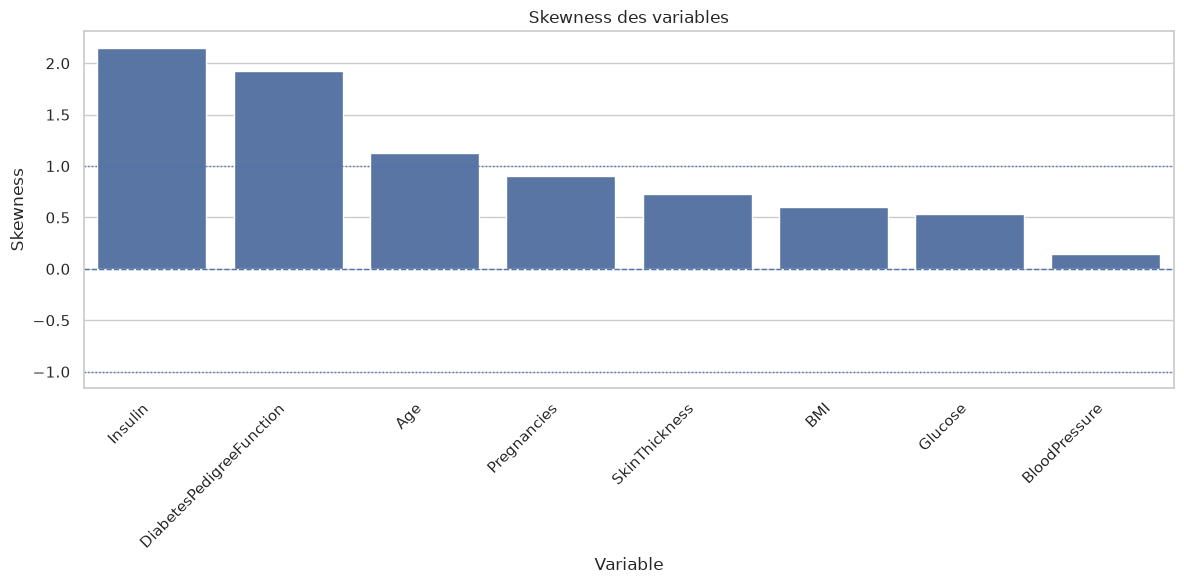

In [108]:
plt.figure(figsize=(12, 6))

skew_plot = (
    skewness_report
    .reset_index()
    .rename(columns={"index": "feature"})
)

sns.barplot(
    data=skew_plot,
    x="feature",
    y="skewness"
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.axhline(
    1,
    linestyle=":",
    linewidth=1
)

plt.axhline(
    -1,
    linestyle=":",
    linewidth=1
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.title(
    "Skewness des variables"
)

plt.xlabel("Variable")
plt.ylabel("Skewness")

plt.tight_layout()
plt.show()

## 34. Identification des variables candidates aux transformations

Nous ne transformons pas automatiquement toutes les variables.

Une transformation est principalement envisagée lorsqu'une variable présente une asymétrie importante, en particulier une skewness positive.

Nous utiliserons :

- `log1p(x)` ;
- `sqrt(x)`.

`log1p(x)` est particulièrement utile lorsque les valeurs sont positives ou nulles.

La transformation racine carrée est généralement moins agressive.

### Règle

Une transformation sera considérée comme intéressante si :

1. la variable présente une skewness absolue suffisamment élevée ;
2. la transformation réduit cette asymétrie ;
3. la réduction est suffisamment importante ;
4. la transformation ne produit pas de valeurs invalides.

`Pregnancies` est un cas particulier : il s'agit d'une variable de comptage. Même si une transformation réduit la skewness, sa transformation ne sera pas automatiquement adoptée sans validation ultérieure sur le clustering.

In [109]:
SKEW_CANDIDATE_THRESHOLD = 1.0
MIN_SKEW_REDUCTION = 0.20

TRANSFORMATION_PROTECTED = [
    "Pregnancies"
]

transformation_records = []

for column in EXPECTED_FEATURES:

    original = df_clean[column]

    skew_original = original.skew()

    log_skew = np.nan
    sqrt_skew = np.nan

    if (original >= 0).all():

        log_values = np.log1p(original)
        sqrt_values = np.sqrt(original)

        log_skew = log_values.skew()
        sqrt_skew = sqrt_values.skew()

    best_transform = "keep"

    if abs(skew_original) >= SKEW_CANDIDATE_THRESHOLD:

        candidates = {
            "keep": abs(skew_original),
            "log1p": abs(log_skew),
            "sqrt": abs(sqrt_skew),
        }

        best_candidate = min(
            candidates,
            key=candidates.get
        )

        improvement = (
            abs(skew_original)
            - candidates[best_candidate]
        ) / abs(skew_original)

        if (
            best_candidate != "keep"
            and improvement >= MIN_SKEW_REDUCTION
        ):
            best_transform = best_candidate

    transformation_records.append({
        "feature": column,
        "skew_original": skew_original,
        "skew_log1p": log_skew,
        "skew_sqrt": sqrt_skew,
        "recommended_transform": best_transform,
    })

transformation_report = pd.DataFrame(
    transformation_records
)

display(transformation_report)

,feature,skew_original,skew_log1p,skew_sqrt,recommended_transform
0,Pregnancies,0.901674,-0.243478,-0.158938,keep
1,Glucose,0.534089,-0.057247,0.253523,keep
2,BloodPressure,0.148346,-0.780031,-0.274380,keep
3,SkinThickness,0.729343,-0.592093,-0.021615,keep
4,Insulin,2.152685,-0.384020,0.786475,log1p
5,BMI,0.603576,-0.032050,0.260926,keep
6,DiabetesPedigreeFunction,1.919911,1.117942,0.901802,sqrt
7,Age,1.129597,0.614664,0.850598,log1p


## 35. Décision finale concernant les transformations

L'analyse de skewness permet d'identifier les variables dont les distributions présentent une forte asymétrie.

Les résultats obtenus sont :

| Feature | Skewness | log1p | sqrt | Décision |
|---|---:|---:|---:|---|
| Pregnancies | 0.902 | -0.243 | -0.159 | Keep |
| Glucose | 0.534 | -0.057 | 0.254 | Keep |
| BloodPressure | 0.148 | -0.780 | -0.274 | Keep |
| SkinThickness | 0.729 | -0.592 | -0.022 | Keep |
| Insulin | 2.153 | -0.384 | 0.786 | log1p |
| BMI | 0.604 | -0.032 | 0.261 | Keep |
| DiabetesPedigreeFunction | 1.920 | 1.118 | 0.902 | sqrt |
| Age | 1.130 | 0.615 | 0.851 | log1p |

### Décision retenue

Nous appliquerons :

- `log1p` à `Insulin` ;
- `sqrt` à `DiabetesPedigreeFunction` ;
- `log1p` à `Age`.

Les autres variables resteront inchangées.

### Justification

`Insulin` présente une forte asymétrie positive. La transformation logarithmique réduit fortement cette asymétrie.

`DiabetesPedigreeFunction` présente également une forte asymétrie positive. La racine carrée donne ici une meilleure réduction de l'asymétrie que `log1p`.

`Age` présente une asymétrie importante. `log1p` fournit la meilleure réduction parmi les deux transformations testées.

Les autres variables ne dépassent pas le seuil de skewness utilisé dans cette analyse ou ne nécessitent pas de transformation selon la règle définie.

La transformation n'a pas pour objectif de supprimer les observations extrêmes. Elle vise à rendre leur représentation moins dominée par les longues queues des distributions.

In [110]:
TRANSFORMATION_MAP = {
    "Insulin": "log1p",
    "DiabetesPedigreeFunction": "sqrt",
    "Age": "log1p",
}

print("Transformations retenues :")

for feature, transformation in TRANSFORMATION_MAP.items():
    print(
        f"✓ {feature}: {transformation}"
    )

print("\nFeatures conservées sans transformation :")

for feature in EXPECTED_FEATURES:
    if feature not in TRANSFORMATION_MAP:
        print(
            f"✓ {feature}: keep"
        )

Transformations retenues :
✓ Insulin: log1p
✓ DiabetesPedigreeFunction: sqrt
✓ Age: log1p

Features conservées sans transformation :
✓ Pregnancies: keep
✓ Glucose: keep
✓ BloodPressure: keep
✓ SkinThickness: keep
✓ BMI: keep


## 36. Comparaison des distributions avant et après transformation

Nous comparons visuellement les trois variables sélectionnées avant et après transformation.

L'objectif est de vérifier :

- la compression des longues queues ;
- la réduction de l'asymétrie ;
- l'absence de comportement manifestement anormal ;
- la conservation de la structure générale des observations.

Cette étape complète l'analyse numérique de la skewness.

In [111]:
df_transformed = df_clean.copy()

for feature, transformation in TRANSFORMATION_MAP.items():

    if transformation == "log1p":
        df_transformed[feature] = np.log1p(
            df_transformed[feature]
        )

    elif transformation == "sqrt":
        df_transformed[feature] = np.sqrt(
            df_transformed[feature]
        )

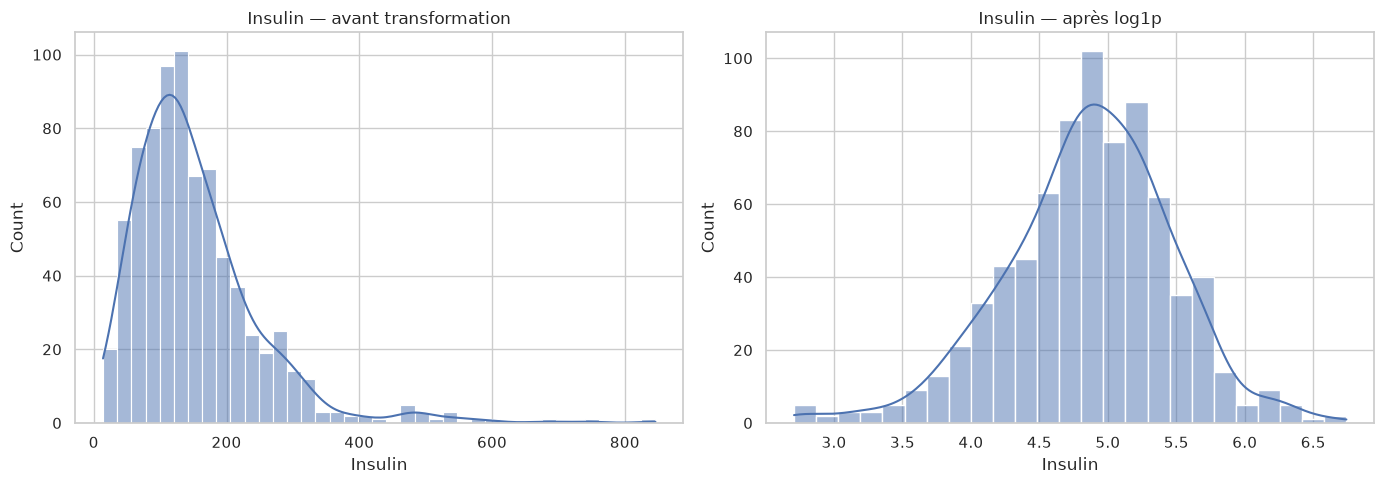

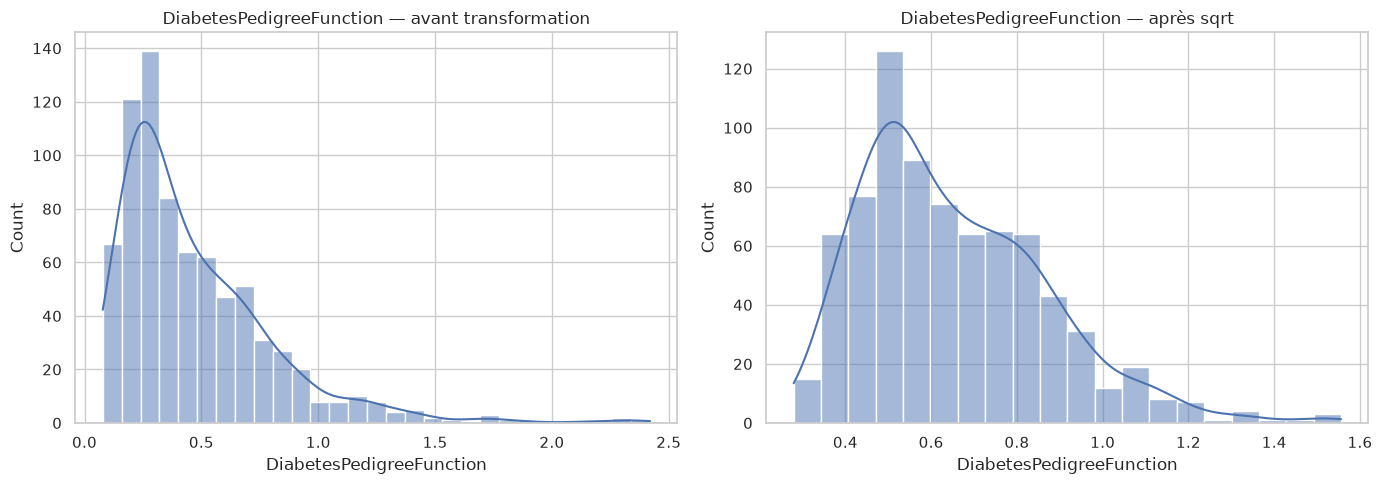

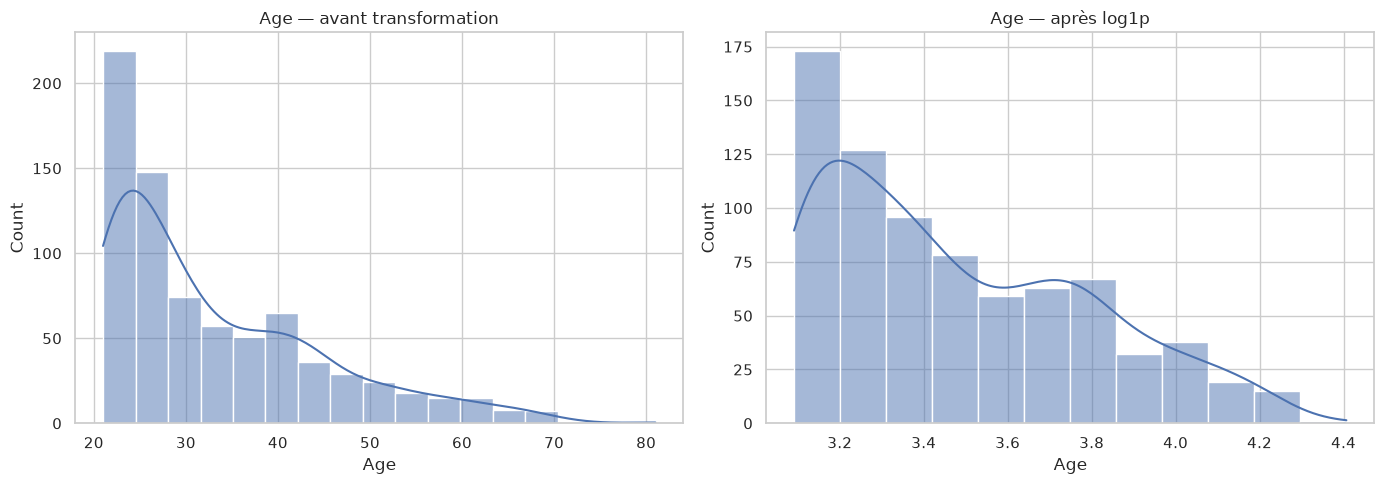

In [112]:
for feature in TRANSFORMATION_MAP:

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 5)
    )

    sns.histplot(
        df_clean[feature],
        kde=True,
        ax=axes[0]
    )

    axes[0].set_title(
        f"{feature} — avant transformation"
    )

    sns.histplot(
        df_transformed[feature],
        kde=True,
        ax=axes[1]
    )

    axes[1].set_title(
        f"{feature} — après {TRANSFORMATION_MAP[feature]}"
    )

    plt.tight_layout()
    plt.show()

## 37. Vérification quantitative des transformations

Nous recalculons la skewness après transformation.

Une transformation est considérée comme utile lorsqu'elle diminue sensiblement la valeur absolue de la skewness.

Nous comparons donc :

- skewness avant ;
- skewness après ;
- réduction absolue ;
- réduction en pourcentage.

In [113]:
transformation_effect_report = []

for feature in EXPECTED_FEATURES:

    before = df_clean[feature].skew()
    after = df_transformed[feature].skew()

    absolute_reduction = (
        abs(before) - abs(after)
    )

    percentage_reduction = np.nan

    if abs(before) != 0:
        percentage_reduction = (
            absolute_reduction
            / abs(before)
            * 100
        )

    transformation_effect_report.append({
        "feature": feature,
        "skew_before": before,
        "skew_after": after,
        "absolute_reduction": absolute_reduction,
        "reduction_percentage": percentage_reduction,
        "transformation": TRANSFORMATION_MAP.get(
            feature,
            "keep"
        ),
    })

transformation_effect_report = pd.DataFrame(
    transformation_effect_report
)

display(
    transformation_effect_report
)

,feature,skew_before,skew_after,absolute_reduction,reduction_percentage,transformation
0,Pregnancies,0.901674,0.901674,0.000000,0.000000,keep
1,Glucose,0.534089,0.534089,0.000000,0.000000,keep
2,BloodPressure,0.148346,0.148346,0.000000,0.000000,keep
3,SkinThickness,0.729343,0.729343,0.000000,0.000000,keep
4,Insulin,2.152685,-0.384020,1.768665,82.160888,log1p
5,BMI,0.603576,0.603576,0.000000,0.000000,keep
6,DiabetesPedigreeFunction,1.919911,0.901802,1.018109,53.028985,sqrt
7,Age,1.129597,0.614664,0.514932,45.585510,log1p


## 38. Validation des valeurs après transformation

Les transformations doivent préserver la validité numérique du dataset.

Nous vérifions :

- l'absence de `NaN` ;
- l'absence de valeurs infinies ;
- l'absence de valeurs négatives créées par erreur ;
- la conservation des dimensions.

In [114]:
print(
    "NaN :",
    df_transformed.isna().sum().sum()
)

print(
    "Infinités :",
    np.isinf(
        df_transformed.to_numpy()
    ).sum()
)

print(
    "Dimensions :",
    df_transformed.shape
)

NaN : 0
Infinités : 0
Dimensions : (768, 8)


In [115]:
assert df_transformed.isna().sum().sum() == 0

assert np.isfinite(
    df_transformed.to_numpy()
).all()

print(
    "✅ Dataset transformé valide."
)

✅ Dataset transformé valide.


## 39. Comparaison des outliers avant et après transformation

Une transformation logarithmique ou racine carrée compresse les grandes valeurs.

Nous recalculons donc les outliers IQR après transformation.

L'objectif n'est pas de supprimer les outliers mais d'observer comment la transformation modifie leur influence statistique.

Une diminution du nombre d'outliers après transformation est attendue pour certaines distributions fortement asymétriques.

In [116]:
def iqr_outlier_report(
    data: pd.DataFrame,
    features: list[str]
) -> pd.DataFrame:

    records = []

    for feature in features:

        q1 = data[feature].quantile(0.25)
        q3 = data[feature].quantile(0.75)

        iqr = q3 - q1

        lower_bound = (
            q1 - 1.5 * iqr
        )

        upper_bound = (
            q3 + 1.5 * iqr
        )

        mask = (
            (data[feature] < lower_bound)
            |
            (data[feature] > upper_bound)
        )

        records.append({
            "feature": feature,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "outlier_count": int(mask.sum()),
            "outlier_percentage": (
                mask.mean() * 100
            ),
        })

    return pd.DataFrame(records)

In [117]:
outliers_before_transform = (
    iqr_outlier_report(
        df_clean,
        EXPECTED_FEATURES
    )
)

outliers_after_transform = (
    iqr_outlier_report(
        df_transformed,
        EXPECTED_FEATURES
    )
)

outlier_comparison = (
    outliers_before_transform[
        [
            "feature",
            "outlier_count",
            "outlier_percentage"
        ]
    ]
    .merge(
        outliers_after_transform[
            [
                "feature",
                "outlier_count",
                "outlier_percentage"
            ]
        ],
        on="feature",
        suffixes=(
            "_before",
            "_after"
        )
    )
)

display(
    outlier_comparison
)

,feature,outlier_count_before,outlier_percentage_before,outlier_count_after,outlier_percentage_after
0,Pregnancies,4,0.520833,4,0.520833
1,Glucose,0,0.000000,0,0.000000
2,BloodPressure,14,1.822917,14,1.822917
3,SkinThickness,4,0.520833,4,0.520833
4,Insulin,27,3.515625,18,2.343750
5,BMI,8,1.041667,8,1.041667
6,DiabetesPedigreeFunction,29,3.776042,10,1.302083
7,Age,9,1.171875,0,0.000000


## 40. Visualisation des distributions transformées

Nous visualisons les boxplots après transformation afin de vérifier l'effet de la compression des longues queues.

Les observations restent toutes présentes.

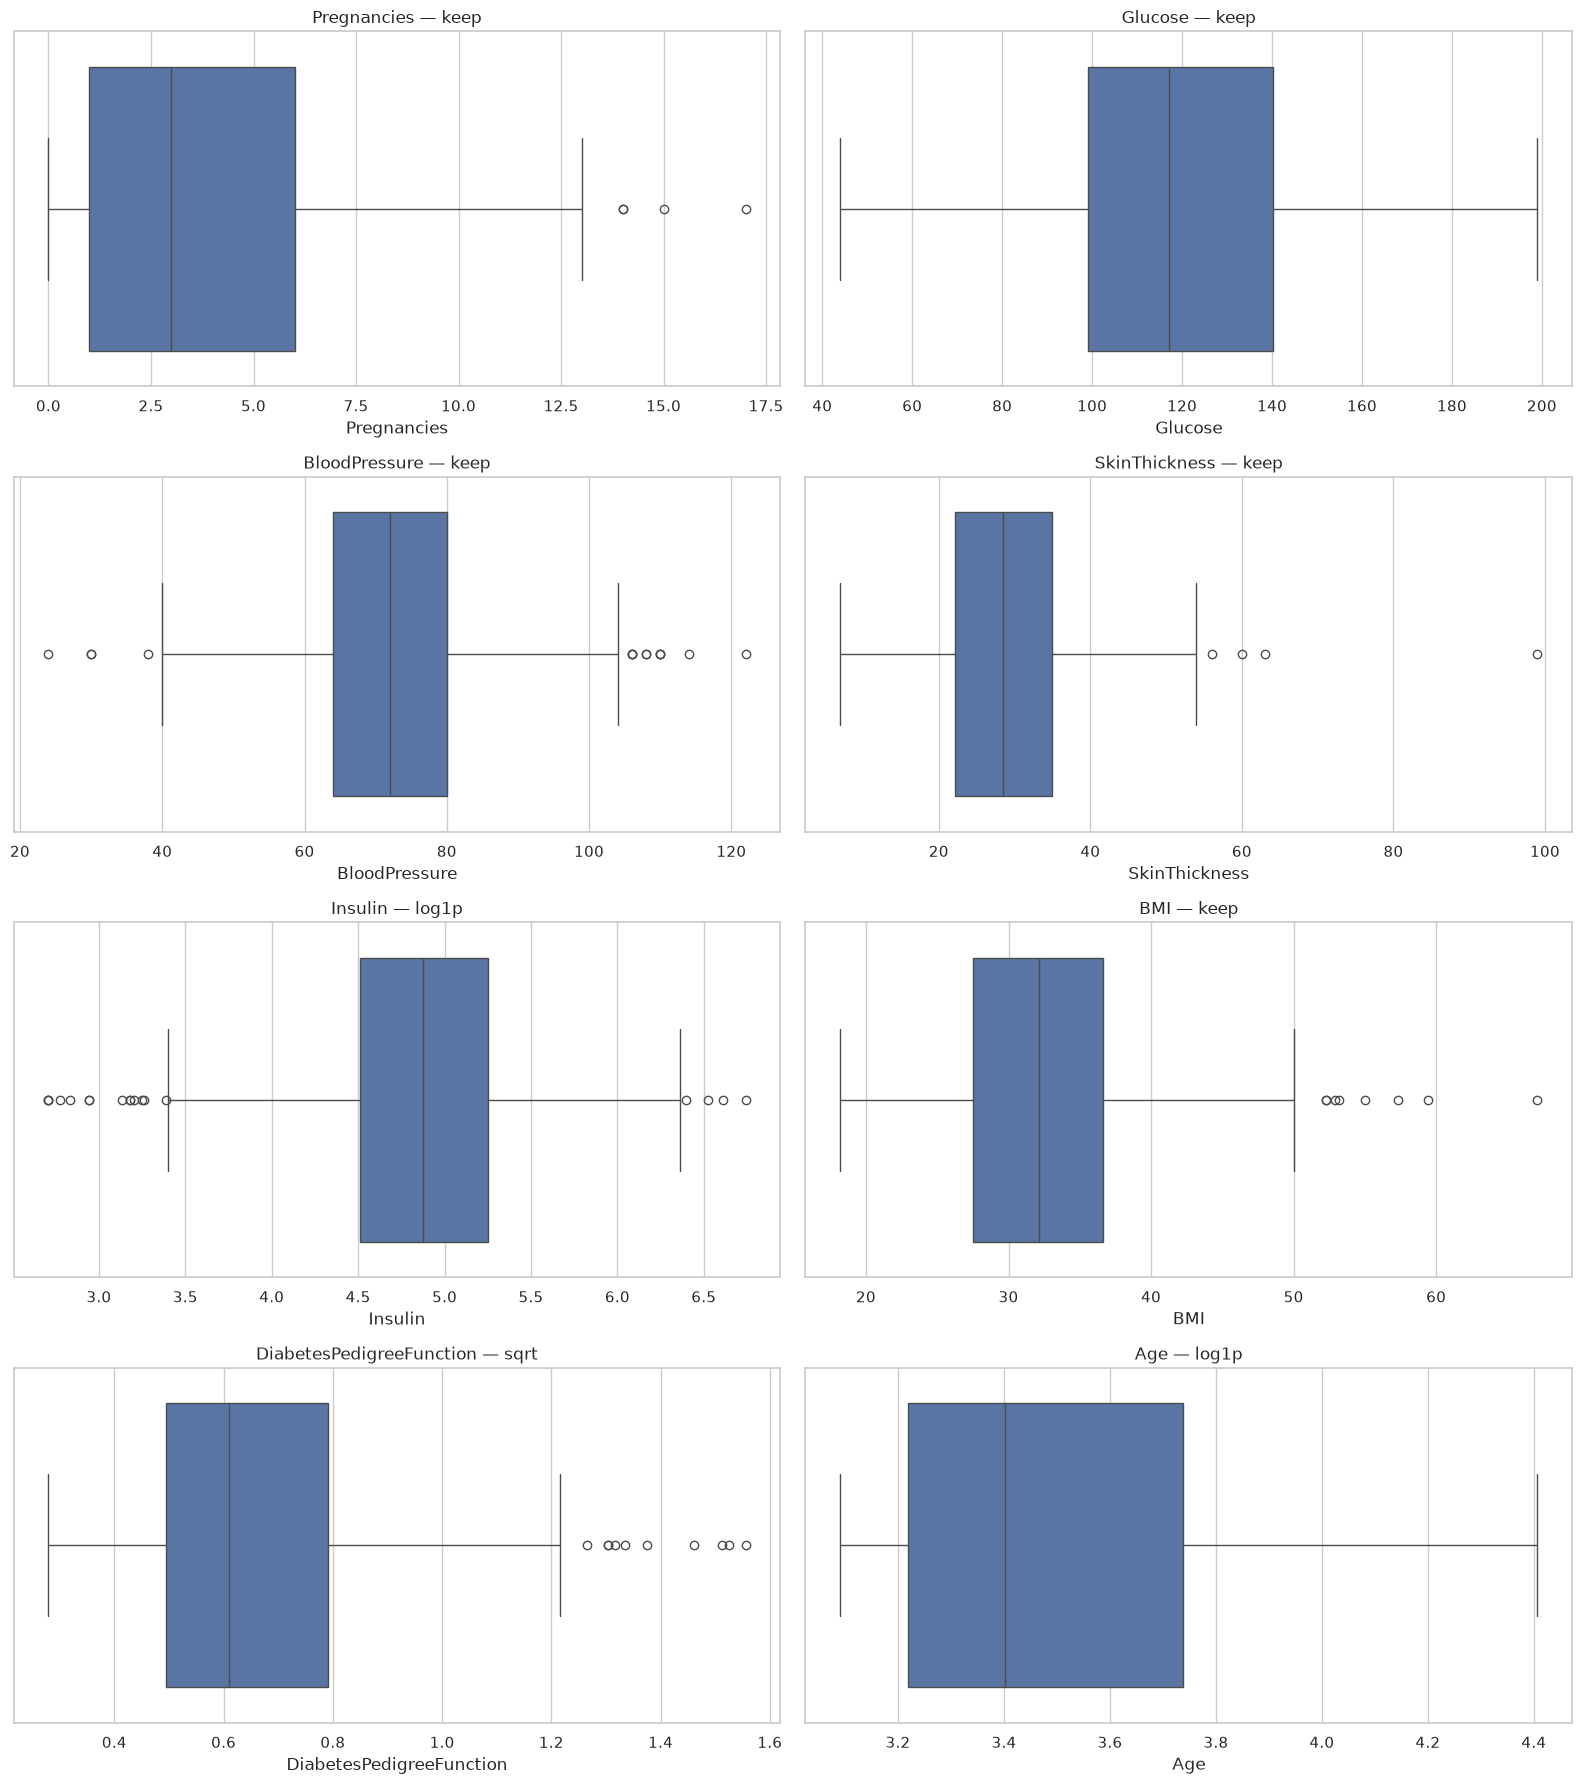

In [118]:
fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(16, 18)
)

axes = axes.flatten()

for ax, feature in zip(
    axes,
    EXPECTED_FEATURES
):

    sns.boxplot(
        x=df_transformed[feature],
        ax=ax
    )

    transformation = TRANSFORMATION_MAP.get(
        feature,
        "keep"
    )

    ax.set_title(
        f"{feature} — {transformation}"
    )

plt.tight_layout()
plt.show()

## 41. Décision finale concernant les outliers

Après transformation, certains outliers statistiques peuvent encore être présents.

Nous ne les supprimons pas automatiquement.

### Pourquoi ?

Le dataset est biomédical et les observations extrêmes peuvent correspondre à des profils réels.

De plus, le but du projet est précisément d'identifier des profils de patients.

Supprimer les observations extrêmes avant le clustering pourrait donc modifier artificiellement la structure naturelle du dataset.

### Traitement retenu

Les outliers seront :

- détectés ;
- documentés ;
- conservés.

Les transformations `log1p` et `sqrt` permettent de réduire l'effet des longues queues sur certaines variables.

Le scaling sera appliqué ensuite.

Pour K-Means, nous comparerons notamment :

- StandardScaler ;
- RobustScaler.

Le scaler final sera sélectionné expérimentalement selon son impact sur la qualité et la stabilité du clustering.

## 42. Corrélations de Pearson après transformation

Nous calculons maintenant les corrélations de Pearson sur la représentation destinée au Machine Learning.

Pearson mesure principalement les relations linéaires.

La matrice permettra d'identifier :

- les associations positives ;
- les associations négatives ;
- les éventuelles variables redondantes.

In [119]:
pearson_corr = df_transformed.corr(
    method="pearson"
)

display(
    pearson_corr
)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Pregnancies,1.000000,0.130107,0.213573,0.107061,0.109965,0.023769,-0.030336,0.588648
Glucose,0.130107,1.000000,0.230501,0.243470,0.734675,0.235509,0.128853,0.277336
BloodPressure,0.213573,0.230501,1.000000,0.242719,0.176218,0.296377,0.004594,0.351183
SkinThickness,0.107061,0.243470,0.242719,1.000000,0.266744,0.706137,0.113522,0.178149
Insulin,0.109965,0.734675,0.176218,0.266744,1.000000,0.293401,0.098580,0.256260
BMI,0.023769,0.235509,0.296377,0.706137,0.293401,1.000000,0.150136,0.060142
DiabetesPedigreeFunction,-0.030336,0.128853,0.004594,0.113522,0.098580,0.150136,1.000000,0.043436
Age,0.588648,0.277336,0.351183,0.178149,0.256260,0.060142,0.043436,1.000000


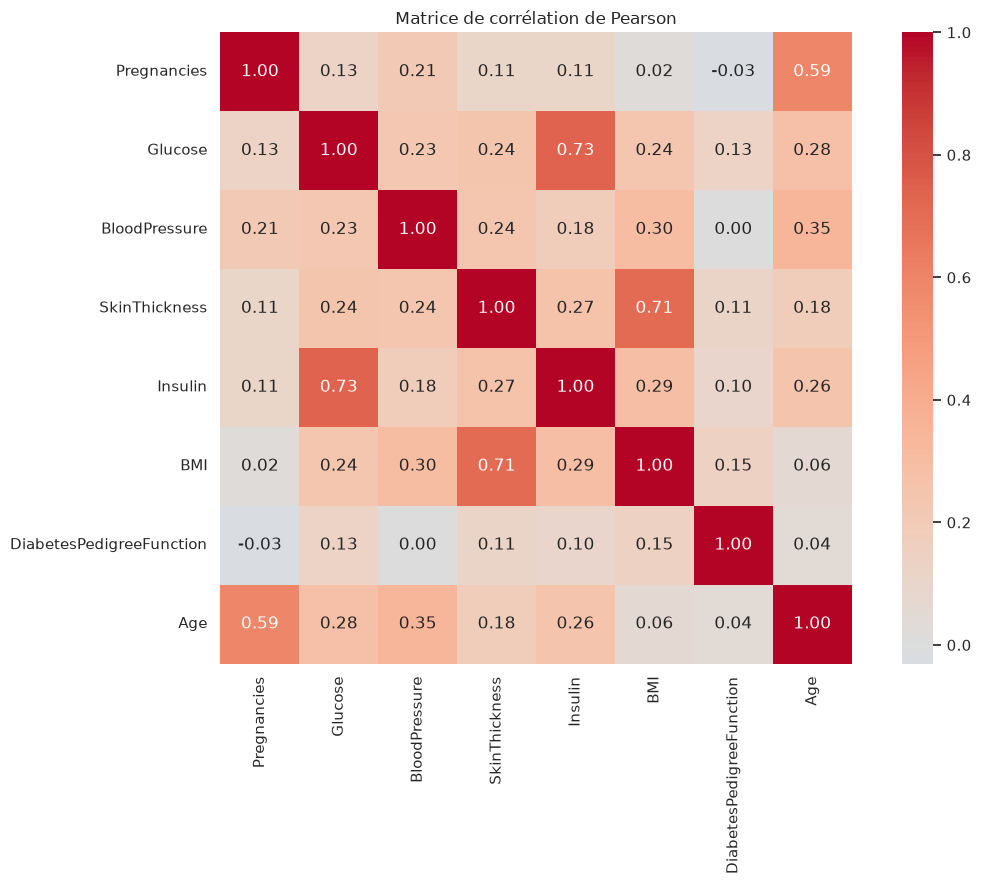

In [120]:
plt.figure(
    figsize=(12, 9)
)

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title(
    "Matrice de corrélation de Pearson"
)

plt.tight_layout()
plt.show()

## 43. Corrélations de Spearman

Pearson mesure principalement les relations linéaires.

Nous complétons donc l'analyse avec Spearman, qui mesure les relations monotones à partir des rangs.

Cette analyse est particulièrement utile dans notre dataset car certaines variables présentent des distributions asymétriques.

L'utilisation conjointe de Pearson et Spearman permet d'éviter de baser la détection de redondance sur une seule mesure.

In [121]:
spearman_corr = df_transformed.corr(
    method="spearman"
)

display(
    spearman_corr
)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Pregnancies,1.000000,0.132248,0.193130,0.108256,0.121847,0.003913,-0.043242,0.607216
Glucose,0.132248,1.000000,0.260707,0.250910,0.789844,0.231890,0.092774,0.286265
BloodPressure,0.193130,0.260707,1.000000,0.274314,0.206313,0.309781,0.020209,0.380389
SkinThickness,0.108256,0.250910,0.274314,1.000000,0.309401,0.750176,0.086415,0.223751
Insulin,0.121847,0.789844,0.206313,0.309401,1.000000,0.327542,0.095172,0.284698
BMI,0.003913,0.231890,0.309781,0.750176,0.327542,1.000000,0.134157,0.125256
DiabetesPedigreeFunction,-0.043242,0.092774,0.020209,0.086415,0.095172,0.134157,1.000000,0.042909
Age,0.607216,0.286265,0.380389,0.223751,0.284698,0.125256,0.042909,1.000000


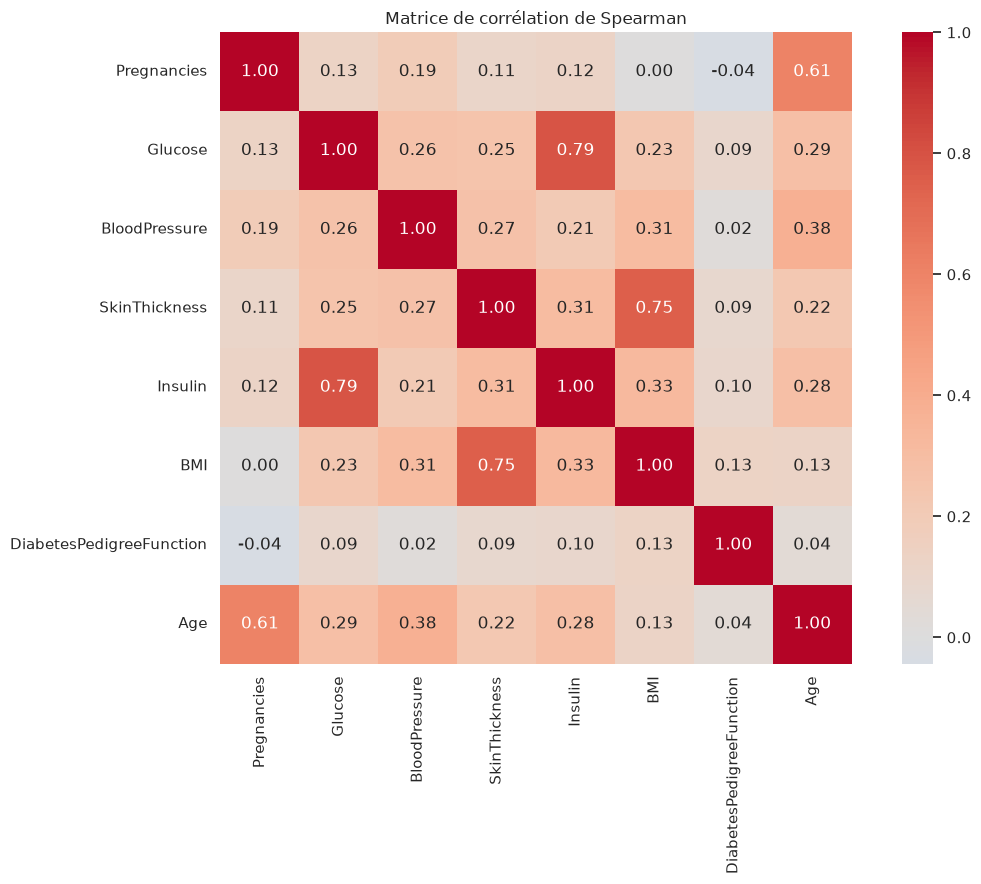

In [122]:
plt.figure(
    figsize=(12, 9)
)

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title(
    "Matrice de corrélation de Spearman"
)

plt.tight_layout()
plt.show()

## 44. Comparaison Pearson vs Spearman

La différence entre Pearson et Spearman peut fournir une information supplémentaire.

Si les deux coefficients sont proches, la relation entre deux variables est relativement cohérente avec une relation monotone.

Une différence importante peut indiquer une relation non linéaire, l'influence de valeurs extrêmes ou une forte asymétrie.

Nous utilisons cette comparaison comme outil exploratoire et non comme règle automatique de suppression.

In [123]:
correlation_difference = (
    pearson_corr
    - spearman_corr
)

display(
    correlation_difference.round(3)
)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Pregnancies,0.000,-0.002,0.020,-0.001,-0.012,0.020,0.013,-0.019
Glucose,-0.002,0.000,-0.030,-0.007,-0.055,0.004,0.036,-0.009
BloodPressure,0.020,-0.030,0.000,-0.032,-0.030,-0.013,-0.016,-0.029
SkinThickness,-0.001,-0.007,-0.032,0.000,-0.043,-0.044,0.027,-0.046
Insulin,-0.012,-0.055,-0.030,-0.043,0.000,-0.034,0.003,-0.028
BMI,0.020,0.004,-0.013,-0.044,-0.034,0.000,0.016,-0.065
DiabetesPedigreeFunction,0.013,0.036,-0.016,0.027,0.003,0.016,0.000,0.001
Age,-0.019,-0.009,-0.029,-0.046,-0.028,-0.065,0.001,0.000


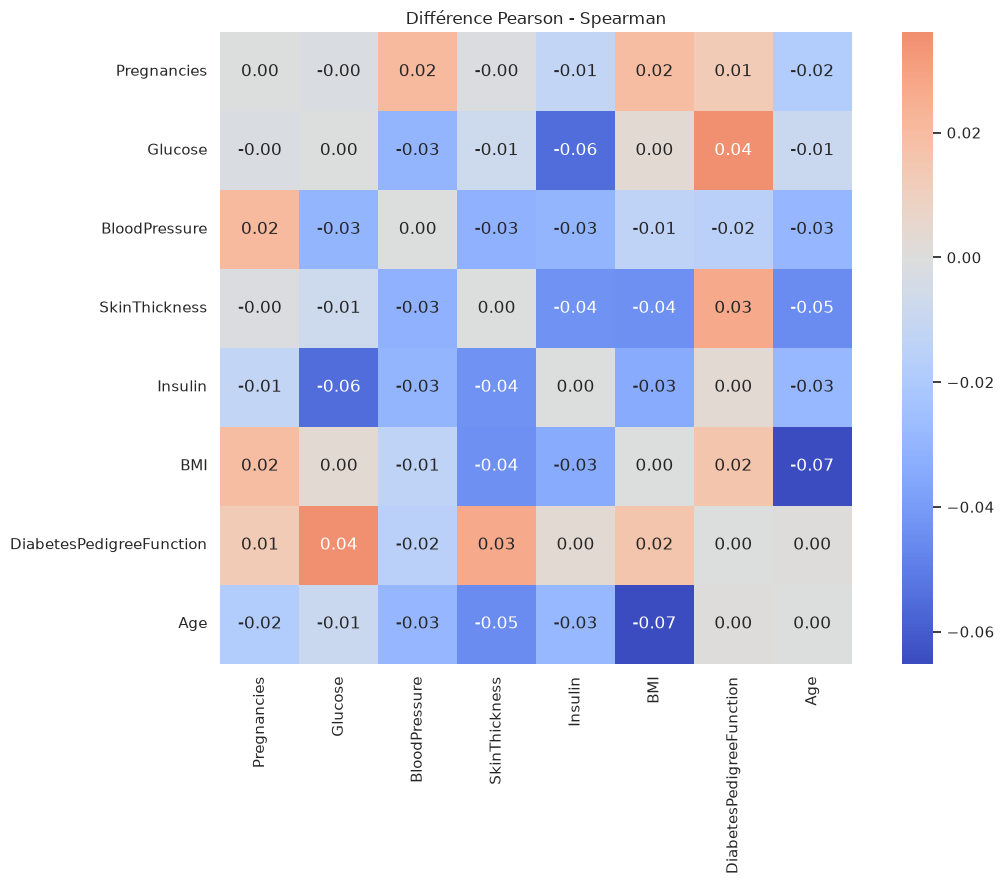

In [124]:
plt.figure(
    figsize=(12, 9)
)

sns.heatmap(
    correlation_difference,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title(
    "Différence Pearson - Spearman"
)

plt.tight_layout()
plt.show()

## 45. Identification des relations fortes entre variables

Après l'analyse de Pearson et de Spearman, nous identifions les paires de variables présentant les corrélations les plus importantes.

Deux niveaux sont utilisés :

- `|corr| >= 0.70` : relation forte ou notable ;
- `|corr| >= 0.80` : relation potentiellement redondante nécessitant une analyse particulière.

Cette étape ne conduit pas automatiquement à supprimer une variable.

Dans un projet de clustering biomédical, deux variables corrélées peuvent représenter une même dimension clinique importante. La décision doit donc également tenir compte de leur intérêt clinique et de leur impact expérimental sur le clustering.

In [126]:
CORRELATION_NOTABLE_THRESHOLD = 0.70
CORRELATION_REDUNDANCY_THRESHOLD = 0.80


def extract_correlation_pairs(
    correlation_matrix: pd.DataFrame,
    threshold: float = 0.70
) -> pd.DataFrame:

    records = []

    features = correlation_matrix.columns

    for i, feature_1 in enumerate(features):
        for feature_2 in features[i + 1:]:

            correlation = correlation_matrix.loc[
                feature_1,
                feature_2
            ]

            if abs(correlation) >= threshold:
                records.append({
                    "feature_1": feature_1,
                    "feature_2": feature_2,
                    "correlation": correlation,
                    "absolute_correlation": abs(correlation)
                })

    columns = [
        "feature_1",
        "feature_2",
        "correlation",
        "absolute_correlation"
    ]

    result = pd.DataFrame(records, columns=columns)

    return result.sort_values(
        by="absolute_correlation",
        ascending=False
    ).reset_index(drop=True)

strong_pearson_pairs = extract_correlation_pairs(
    pearson_corr,
    threshold=CORRELATION_NOTABLE_THRESHOLD
)

strong_spearman_pairs = extract_correlation_pairs(
    spearman_corr,
    threshold=CORRELATION_NOTABLE_THRESHOLD
)


print("Paires fortement corrélées — Pearson")
display(strong_pearson_pairs)

print("\nPaires fortement corrélées — Spearman")
display(strong_spearman_pairs)


high_redundancy_pearson = extract_correlation_pairs(
    pearson_corr,
    threshold=CORRELATION_REDUNDANCY_THRESHOLD
)

high_redundancy_spearman = extract_correlation_pairs(
    spearman_corr,
    threshold=CORRELATION_REDUNDANCY_THRESHOLD
)

print("\nPaires potentiellement redondantes — Pearson")
display(high_redundancy_pearson)

print("\nPaires potentiellement redondantes — Spearman")
display(high_redundancy_spearman)

Paires fortement corrélées — Pearson


,feature_1,feature_2,correlation,absolute_correlation
0,Glucose,Insulin,0.734675,0.734675
1,SkinThickness,BMI,0.706137,0.706137



Paires fortement corrélées — Spearman


,feature_1,feature_2,correlation,absolute_correlation
0,Glucose,Insulin,0.789844,0.789844
1,SkinThickness,BMI,0.750176,0.750176



Paires potentiellement redondantes — Pearson


,feature_1,feature_2,correlation,absolute_correlation



Paires potentiellement redondantes — Spearman


,feature_1,feature_2,correlation,absolute_correlation


## 46. Analyse bivariée avec Pairplot

Le pairplot permet d'observer simultanément les relations entre les différentes
variables cliniques.

Cette visualisation complète les coefficients de corrélation de Pearson et
Spearman en permettant d'identifier visuellement :

- les tendances linéaires ;
- les tendances monotones ;
- les regroupements éventuels ;
- les valeurs atypiques ;
- les relations non linéaires potentielles.

Les variables utilisées correspondent à la représentation transformée destinée
au clustering.

Le pairplot est utilisé à des fins exploratoires uniquement.
Il ne constitue pas à lui seul une méthode de sélection ou de suppression
de variables.

In [130]:
FEATURES_FOR_MODELING = EXPECTED_FEATURES.copy()

print(
    "Features retenues pour le modeling :"
)

print(
    FEATURES_FOR_MODELING
)

print(
    f"\nNombre de features : "
    f"{len(FEATURES_FOR_MODELING)}"
)

Features retenues pour le modeling :
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Nombre de features : 8


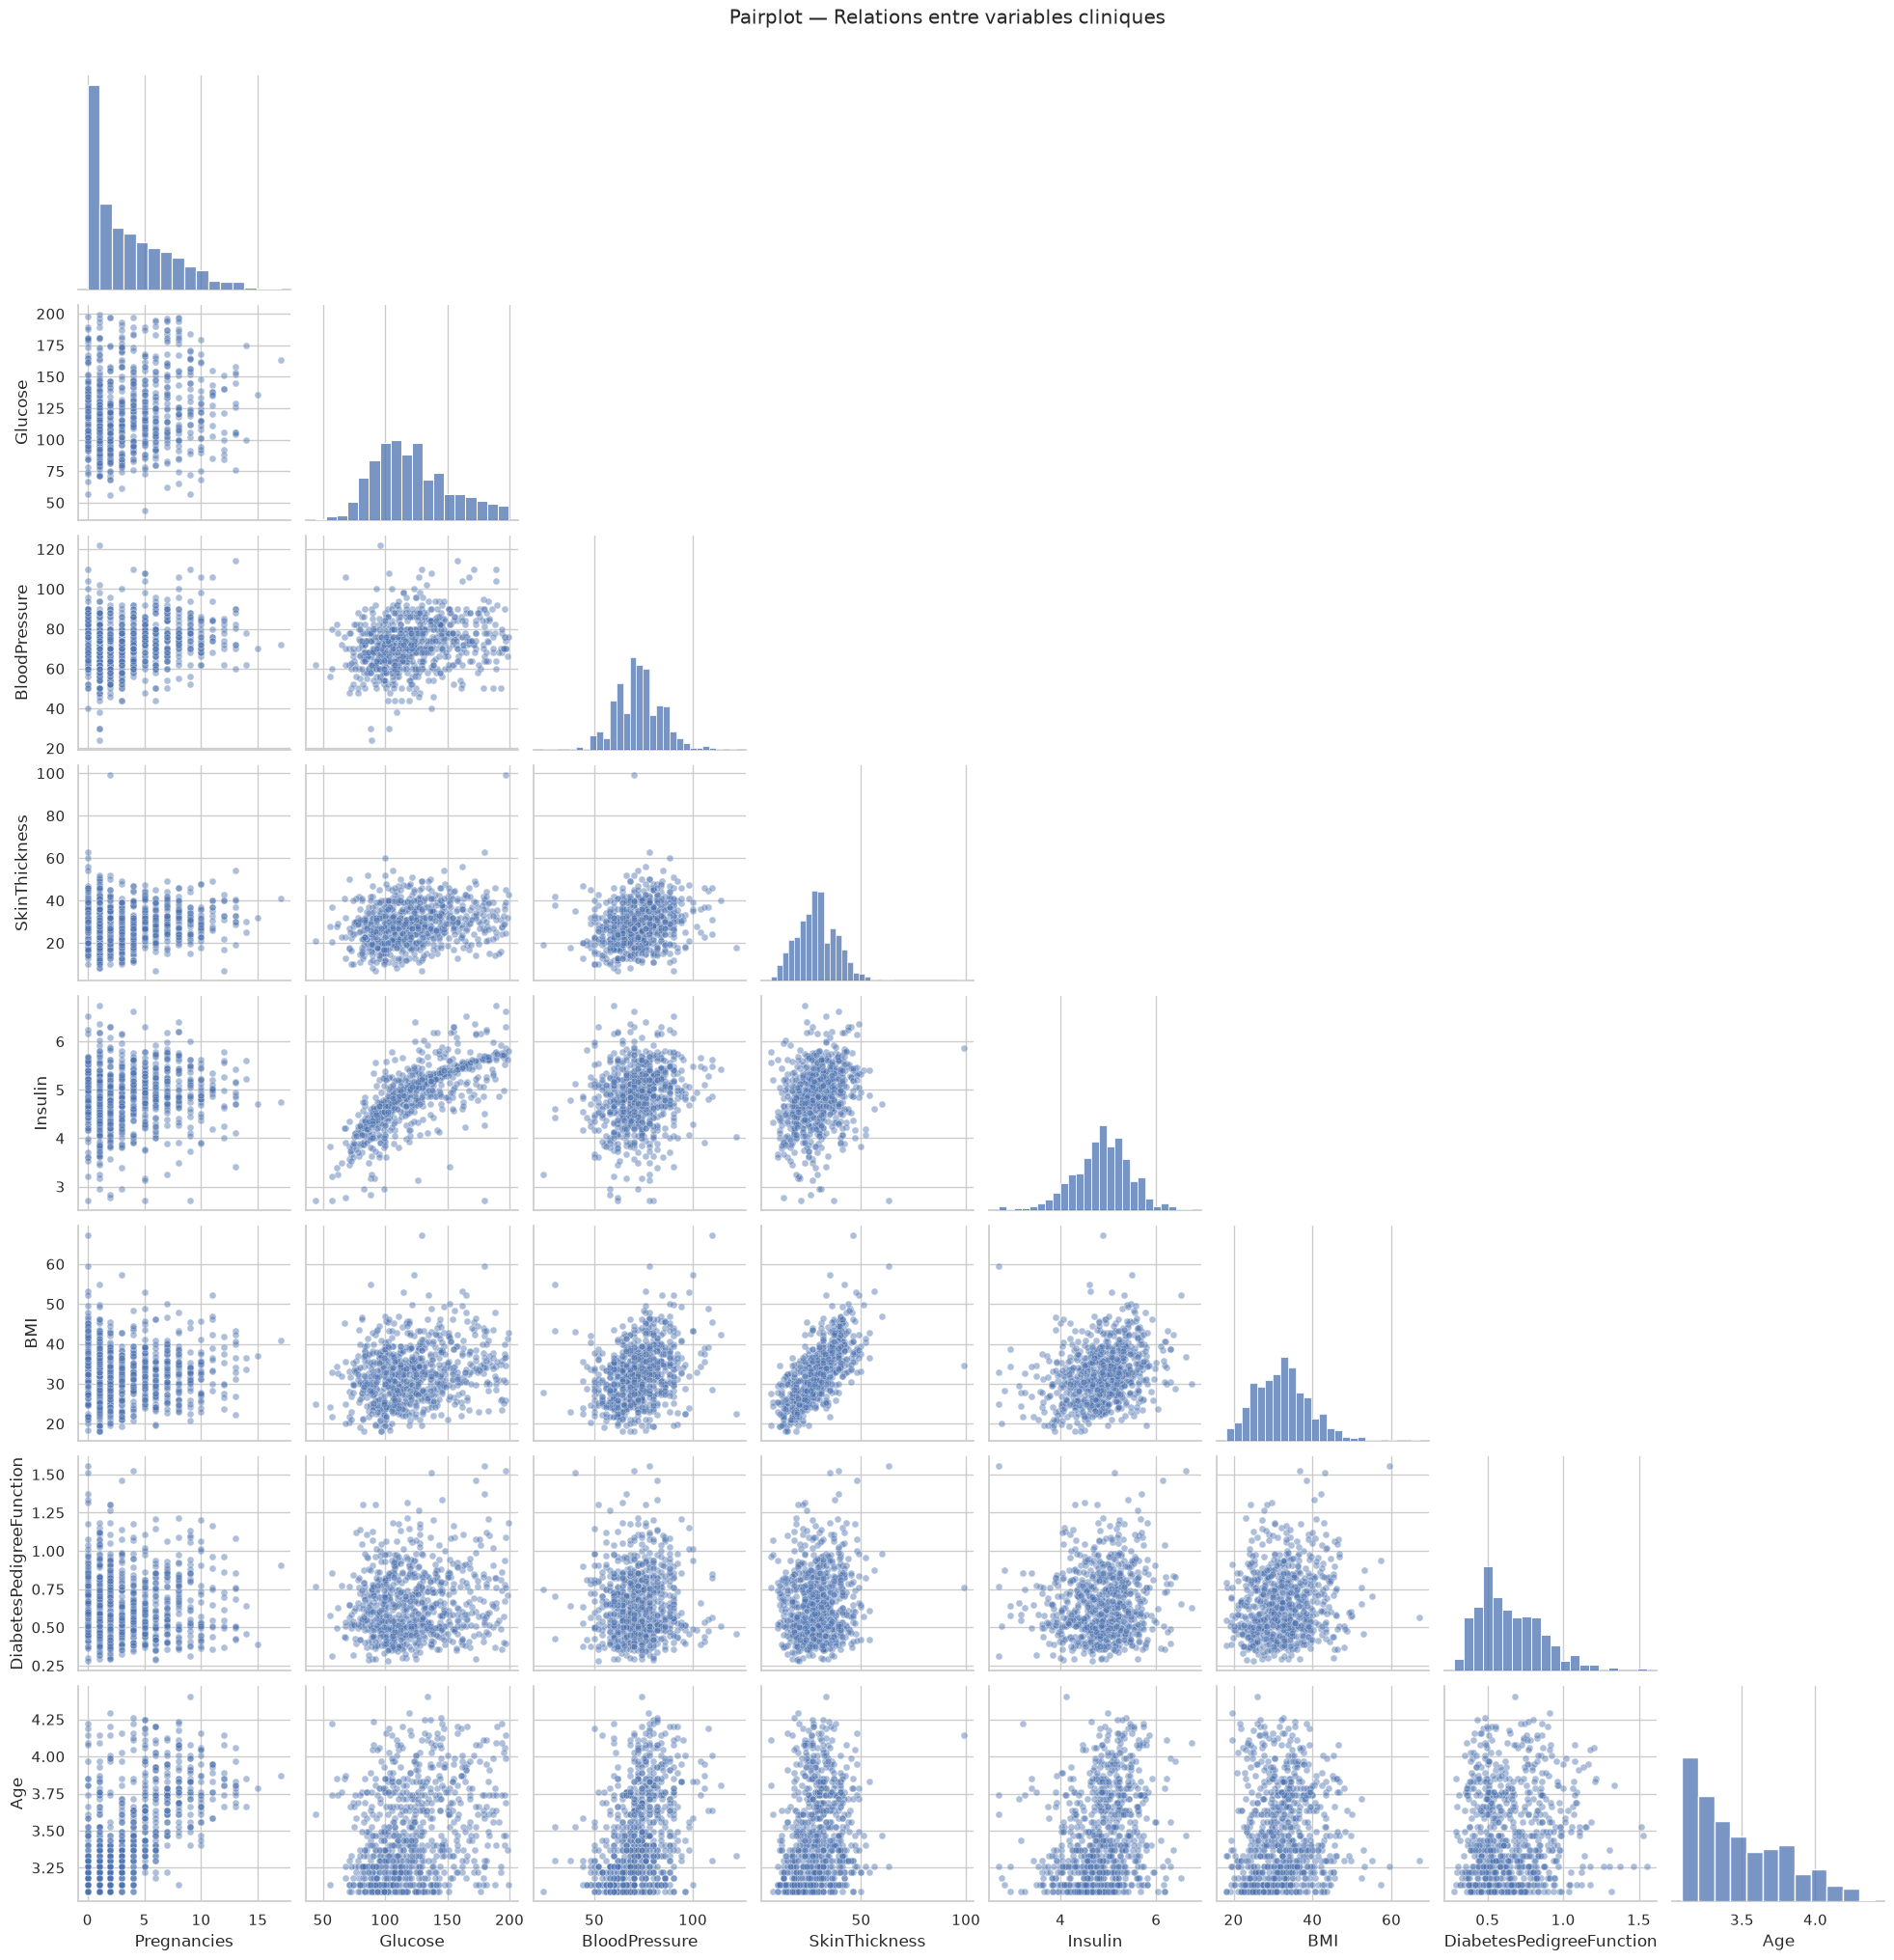

In [131]:
PAIRPLOT_FEATURES = FEATURES_FOR_MODELING.copy()

pairplot = sns.pairplot(
    df_transformed[PAIRPLOT_FEATURES],
    corner=True,
    diag_kind="hist",
    plot_kws={
        "alpha": 0.45,
        "s": 25
    }
)

pairplot.fig.suptitle(
    "Pairplot — Relations entre variables cliniques",
    y=1.02
)

plt.show()

## 47. Analyse de la variabilité des variables

Le projet demande d'identifier les variables présentant la plus grande
variabilité.

Cependant, une comparaison directe des variances brutes serait trompeuse
car les variables utilisent des unités et des échelles très différentes.

Par exemple, Insulin possède naturellement une variance beaucoup plus élevée
que DiabetesPedigreeFunction simplement parce que leurs unités sont différentes.

Nous examinons donc plusieurs indicateurs :

- écart-type ;
- variance ;
- IQR ;
- coefficient de variation.

Cette analyse est descriptive.

Elle ne conduit pas automatiquement à supprimer les variables présentant
une faible variance.

Une feature cliniquement importante peut avoir une faible dispersion et
rester indispensable au clustering.

In [132]:
variability_report = pd.DataFrame({
    "mean": df_clean[EXPECTED_FEATURES].mean(),
    "std": df_clean[EXPECTED_FEATURES].std(),
    "variance": df_clean[EXPECTED_FEATURES].var(),
    "IQR": (
        df_clean[EXPECTED_FEATURES].quantile(0.75)
        - df_clean[EXPECTED_FEATURES].quantile(0.25)
    )
})

variability_report["coefficient_of_variation_%"] = (
    variability_report["std"]
    / variability_report["mean"]
    * 100
)

variability_report = variability_report.sort_values(
    by="std",
    ascending=False
)

display(
    variability_report.round(3)
)

,mean,std,variance,IQR,coefficient_of_variation_%
Insulin,152.694,97.272,9461.861,100.016,63.704
Glucose,121.642,30.467,928.212,41.250,25.046
BloodPressure,72.352,12.147,147.554,16.000,16.789
Age,33.241,11.760,138.303,17.000,35.379
SkinThickness,28.907,9.522,90.667,12.879,32.940
BMI,32.443,6.878,47.310,9.100,21.201
Pregnancies,3.845,3.370,11.354,5.000,87.634
DiabetesPedigreeFunction,0.472,0.331,0.110,0.382,70.215


## 48. Décision de qualité et de sélection des variables

L'analyse précédente est confrontée aux résultats de corrélation.

Les seuils retenus sont :

- |corrélation| >= 0.70 : relation forte / notable ;
- |corrélation| >= 0.80 : redondance potentielle.

Les résultats obtenus montrent :

- aucune paire ne dépasse 0.80 avec Pearson ;
- aucune paire ne dépasse 0.80 avec Spearman ;
- Glucose–Insulin constitue la relation la plus forte ;
- SkinThickness–BMI constitue la deuxième relation la plus forte.

Ces relations restent toutefois sous le seuil défini de redondance.

Aucune variable n'est donc supprimée à ce stade.

Les huit variables sont conservées car elles représentent chacune une
dimension clinique différente et aucune redondance suffisamment forte
n'a été détectée pour justifier leur suppression.

In [133]:
print("Paires redondantes — Pearson :")
display(high_redundancy_pearson)

print("Paires redondantes — Spearman :")
display(high_redundancy_spearman)

if (
    high_redundancy_pearson.empty
    and high_redundancy_spearman.empty
):
    FEATURES_FOR_MODELING = EXPECTED_FEATURES.copy()

    print(
        "✅ Aucune redondance >= 0.80 détectée."
    )
    print(
        "✅ Les 8 variables sont conservées."
    )

else:
    print(
        "⚠️ Des paires potentiellement redondantes "
        "ont été détectées."
    )

Paires redondantes — Pearson :


,feature_1,feature_2,correlation,absolute_correlation


Paires redondantes — Spearman :


,feature_1,feature_2,correlation,absolute_correlation


✅ Aucune redondance >= 0.80 détectée.
✅ Les 8 variables sont conservées.


## 49. Définition des variables finales de modélisation

À l'issue de l'EDA et de l'analyse de corrélation, les variables retenues
pour le clustering sont :

- Pregnancies
- Glucose
- BloodPressure
- SkinThickness
- Insulin
- BMI
- DiabetesPedigreeFunction
- Age

La variable Outcome n'est volontairement pas utilisée.

La représentation destinée au clustering correspond à :

1. gestion des valeurs manquantes ;
2. imputation itérative ;
3. transformations sélectionnées ;
4. scaling.

Les variables conservent leur signification clinique, tandis que leur
représentation numérique est adaptée aux algorithmes basés sur les distances.

In [134]:
FEATURES_FOR_MODELING = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
]

X_model = df_transformed[
    FEATURES_FOR_MODELING
].copy()

print(
    "Features utilisées :",
    FEATURES_FOR_MODELING
)

print(
    "Shape :",
    X_model.shape
)

Features utilisées : ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Shape : (768, 8)


# 50. Conclusion finale — Nettoyage et préparation des données

## Bilan général

L'objectif de ce notebook était de préparer le jeu de données **GlucoProfile** pour les deux étapes de Machine Learning prévues dans le projet :

1. le **clustering non supervisé avec K-Means** ;
2. la **classification supervisée à partir des groupes identifiés**.

Le traitement a été réalisé sans utiliser la variable `Outcome`, conformément à l'objectif de découverte non supervisée des profils de patients.

Le dataset initial contenait **768 observations et 9 colonnes**, dont une colonne d'index `Unnamed: 0`. Après suppression de cette colonne, le dataset final contient **768 observations et 8 variables cliniques** :

* `Pregnancies`
* `Glucose`
* `BloodPressure`
* `SkinThickness`
* `Insulin`
* `BMI`
* `DiabetesPedigreeFunction`
* `Age`

---

## 1. Nettoyage de la structure

La colonne `Unnamed: 0` a été supprimée car elle correspond à un index technique et ne représente aucune information clinique utile.

Les noms de colonnes ont également été nettoyés afin d'éliminer les espaces superflus et les caractères inutiles.

La structure attendue du dataset a été vérifiée :

* aucune variable clinique obligatoire n'est absente ;
* aucune colonne supplémentaire pertinente n'a été conservée ;
* les huit variables retenues sont numériques ;
* le dataset conserve ses **768 observations**.

---

## 2. Gestion des valeurs manquantes

Aucune valeur `NaN` explicite n'était présente dans le dataset original.

Cependant, l'analyse des données a montré que certains `0` représentaient en réalité des mesures absentes pour les variables :

* `Glucose` : **5 valeurs**, soit **0,65 %** ;
* `BloodPressure` : **35 valeurs**, soit **4,56 %** ;
* `SkinThickness` : **227 valeurs**, soit **29,56 %** ;
* `Insulin` : **374 valeurs**, soit **48,70 %** ;
* `BMI` : **11 valeurs**, soit **1,43 %**.

Ces zéros ont donc été convertis en `NaN`.

En revanche, `Pregnancies = 0` a été conservé car cette valeur est valide, tandis que `DiabetesPedigreeFunction = 0` n'a pas été considéré automatiquement comme une donnée manquante.

Après cette conversion, **376 observations** contenaient au moins une valeur manquante, avec un maximum de **4 variables manquantes sur une même observation**.

---

## 3. Validation des valeurs physiologiquement impossibles

Les règles de validité ont été vérifiées pour les huit variables.

Aucune valeur invalide n'a été détectée après la conversion des zéros codant les mesures manquantes en `NaN`.

Les contraintes retenues sont :

* `Pregnancies >= 0`
* `Glucose > 0`
* `BloodPressure > 0`
* `SkinThickness > 0`
* `Insulin > 0`
* `BMI > 0`
* `DiabetesPedigreeFunction >= 0`
* `Age > 0`

Ces règles ont également été utilisées lors de la validation des valeurs imputées.

---

## 4. Doublons

La recherche des doublons exacts a retourné :

**0 doublon**

Aucune observation n'a donc été supprimée.

Le dataset conserve ainsi ses **768 observations** originales.

---

## 5. Stratégie d'imputation retenue

Plusieurs méthodes ont été comparées expérimentalement :

* Mean ;
* Median ;
* KNN ;
* IterativeImputer.

L'évaluation a été réalisée en masquant artificiellement une partie des valeurs connues puis en comparant les valeurs reconstruites aux valeurs réelles.

La métrique principale utilisée pour comparer les variables de différentes échelles est la **Relative MAE**, définie par rapport à la meilleure MAE obtenue pour chaque variable.

Les résultats montrent que **IterativeImputer est la meilleure méthode pour chacune des cinq variables incomplètes** :

| Variable        | Méthode retenue  |
| --------------- | ---------------- |
| `Glucose`       | IterativeImputer |
| `BloodPressure` | IterativeImputer |
| `SkinThickness` | IterativeImputer |
| `Insulin`       | IterativeImputer |
| `BMI`           | IterativeImputer |

La comparaison globale confirme également cette décision :

* Iterative : **1.000**
* KNN : **1.090**
* Median : **1.274**
* Mean : **1.299**

Plus la Relative MAE est faible, meilleure est la reconstruction.

### Décision finale

**IterativeImputer est retenu pour l'imputation finale.**

Une contrainte supplémentaire a ensuite été appliquée car la première imputation produisait une valeur négative pour `Insulin` (`-19.51`), ce qui est incompatible avec la définition de cette variable.

L'imputation finale a donc été réappliquée avec des bornes inférieure et supérieure dérivées des valeurs réellement observées avant imputation.

Cette étape permet d'obtenir un dataset complet tout en évitant des estimations incompatibles avec le domaine des variables.

Après imputation contrainte :

* nombre de `NaN` : **0** ;
* nombre de valeurs infinies : **0** ;
* dimensions : **768 × 8** ;
* toutes les contraintes de validité sont satisfaites.

---

## 6. Gestion des outliers

Les outliers ont été détectés avec la méthode **IQR (Interquartile Range)**.

Après imputation contrainte, les principaux outliers statistiques détectés sont :

| Variable                   | Nombre d'outliers | Pourcentage |
| -------------------------- | ----------------: | ----------: |
| `DiabetesPedigreeFunction` |                29 |      3,78 % |
| `Insulin`                  |                27 |      3,52 % |
| `BloodPressure`            |                14 |      1,82 % |
| `Age`                      |                 9 |      1,17 % |
| `BMI`                      |                 8 |      1,04 % |
| `Pregnancies`              |                 4 |      0,52 % |
| `SkinThickness`            |                 4 |      0,52 % |
| `Glucose`                  |                 0 |         0 % |

Ces observations ont été considérées comme des **outliers statistiques**, et non comme des erreurs de mesure.

### Décision finale

Les outliers :

* sont détectés ;
* sont documentés ;
* sont conservés ;
* ne sont pas supprimés ;
* ne sont pas soumis à un clipping arbitraire.

Cette décision est motivée par le contexte biomédical du projet : une observation extrême peut correspondre à un profil patient réel et potentiellement important pour l'identification de groupes à risque.

L'influence de ces valeurs sera plutôt contrôlée au niveau du scaling et du choix du modèle de clustering.

---

## 7. Analyse de l'asymétrie et transformations

L'analyse de la skewness a montré trois distributions particulièrement asymétriques :

* `Insulin` : skewness = **2,153** ;
* `DiabetesPedigreeFunction` : skewness = **1,920** ;
* `Age` : skewness = **1,130**.

Des transformations `log1p` et `sqrt` ont été comparées.

### Transformations retenues

| Variable                   | Avant | Transformation |  Après |
| -------------------------- | ----: | -------------- | -----: |
| `Insulin`                  | 2,153 | `log1p`        | -0,384 |
| `DiabetesPedigreeFunction` | 1,920 | `sqrt`         |  0,902 |
| `Age`                      | 1,130 | `log1p`        |  0,615 |

Les réductions relatives de skewness sont respectivement d'environ :

* `Insulin` : **82,2 %** ;
* `DiabetesPedigreeFunction` : **53,0 %** ;
* `Age` : **45,6 %**.

Les autres variables n'ont pas été transformées.

### Représentation finale

Les transformations appliquées sont donc :

```python
TRANSFORMATION_MAP = {
    "Insulin": "log1p",
    "DiabetesPedigreeFunction": "sqrt",
    "Age": "log1p",
}
```

Cette étape vise à réduire l'effet des longues queues des distributions, et non à supprimer les observations extrêmes.

---

## 8. Effet des transformations sur les outliers

Après transformation, une diminution du nombre d'outliers a été observée pour certaines variables fortement asymétriques :

* `Insulin` : **27 → 18** ;
* `DiabetesPedigreeFunction` : **29 → 10** ;
* `Age` : **9 → 0**.

Les autres variables n'ont pas changé.

Cela confirme que les transformations ont effectivement réduit l'influence statistique des longues queues sans supprimer aucune observation.

---

## 9. Analyse des corrélations

Les matrices de Pearson et de Spearman ont été analysées afin d'identifier les relations fortes et les éventuelles redondances entre variables.

Deux relations principales ont été détectées :

### Glucose — Insulin

* Pearson : **0,735**
* Spearman : **0,790**

### SkinThickness — BMI

* Pearson : **0,706**
* Spearman : **0,750**

Ces relations sont suffisamment importantes pour être documentées, mais elles restent inférieures au seuil de redondance fixé à :

```text
|corrélation| >= 0,80
```

Aucune paire ne dépasse ce seuil, ni avec Pearson ni avec Spearman.

### Décision finale

**Aucune variable n'est supprimée pour redondance.**

Les huit variables sont conservées pour le clustering.

Cette décision permet de préserver la diversité des informations cliniques tout en évitant de supprimer arbitrairement une feature sur la seule base d'une corrélation modérée à forte.

---

## 10. Analyse de la variabilité

L'analyse de la dispersion montre notamment :

* `Insulin` possède le plus grand écart-type absolu ;
* `Glucose` possède également une dispersion importante ;
* `Pregnancies` et `DiabetesPedigreeFunction` présentent un coefficient de variation relativement élevé ;
* les échelles des variables sont très différentes.

Cette différence d'échelle confirme qu'un **scaling est indispensable avant K-Means**, puisque K-Means repose sur des distances entre observations.

Malgré les différences de variabilité, aucune feature n'est supprimée.

Une faible ou forte dispersion ne constitue pas à elle seule une raison suffisante pour éliminer une variable cliniquement pertinente.

---

## 11. Features finales retenues

Les huit variables suivantes sont définitivement retenues comme variables candidates au clustering :

```python
FEATURES_FOR_MODELING = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
]
```

Aucune variable `Outcome` n'est utilisée.

La représentation actuelle destinée au Machine Learning est :

```python
X_model = df_transformed[
    FEATURES_FOR_MODELING
].copy()
```

Elle correspond à :

```text
Données originales
      ↓
Gestion des 0 représentant des valeurs manquantes
      ↓
NaN
      ↓
IterativeImputer contraint
      ↓
Dataset complet et valide
      ↓
log1p / sqrt sur les variables sélectionnées
      ↓
X_model
```

À ce stade, **le scaling n'a pas encore été appliqué**.

---

## 12. Décisions finales avant le clustering

Les décisions prises dans ce notebook sont donc :

| Élément                          | Décision                       |
| -------------------------------- | ------------------------------ |
| Colonne d'index                  | Supprimée                      |
| `Outcome`                        | Non utilisée                   |
| Valeurs explicites `NaN`         | Vérifiées                      |
| Zéros invalides                  | Convertis en `NaN`             |
| Doublons                         | Aucun                          |
| Imputation                       | IterativeImputer               |
| Contraintes d'imputation         | Bornes observées appliquées    |
| Outliers                         | Conservés                      |
| Clipping                         | Aucun                          |
| `Insulin`                        | `log1p`                        |
| `DiabetesPedigreeFunction`       | `sqrt`                         |
| `Age`                            | `log1p`                        |
| Autres variables                 | Conservées sans transformation |
| Corrélation redondante `>= 0,80` | Aucune                         |
| Features retenues                | 8 / 8                          |
| Scaling                          | À déterminer expérimentalement |
| Nombre de clusters `k`           | À déterminer                   |

---

## 13. Données à transmettre au notebook de clustering

Deux représentations doivent être conservées pour la suite du projet.

### `df_clean`

Cette représentation contient les variables dans leurs unités cliniques d'origine après imputation.

Elle sera utilisée principalement pour :

* interpréter les clusters ;
* calculer les moyennes et médianes des groupes ;
* appliquer les seuils de risque ;
* présenter les profils patients dans des unités compréhensibles.

### `df_transformed` / `X_model`

Cette représentation contient les transformations sélectionnées :

* `Insulin → log1p` ;
* `DiabetesPedigreeFunction → sqrt` ;
* `Age → log1p`.

Elle constitue la base de travail pour le clustering, avant scaling.

---

## 14. Prochaine étape : clustering K-Means

Le notebook de nettoyage est maintenant terminé.

Le prochain notebook commencera par la comparaison des stratégies de scaling :

```text
X_model
   ↓
StandardScaler
       VS
RobustScaler
   ↓
Évaluation de K-Means
   ↓
Elbow
   ↓
Silhouette
   ↓
Stabilité du clustering
   ↓
Choix de k
   ↓
K-Means final
```

Le choix du scaler ne sera donc pas imposé à l'avance.

Même si les outliers ont été conservés, `RobustScaler` n'est pas considéré automatiquement comme supérieur : **StandardScaler et RobustScaler seront comparés expérimentalement** afin de déterminer lequel produit la meilleure structure de clustering.

Le nombre final de clusters sera ensuite déterminé à partir de la combinaison de :

* la méthode du coude ;
* le score de silhouette ;
* la stabilité des partitions ;
* la taille des clusters ;
* l'interprétabilité des profils obtenus.

---

## Conclusion

Le dataset GlucoProfile est désormais **nettoyé, complet, valide et prêt pour l'analyse non supervisée**.

Le nettoyage a permis de corriger la représentation des données manquantes sans supprimer d'informations cliniques utiles. L'imputation itérative a été retenue sur la base d'un benchmark quantitatif et contrainte afin d'éviter des valeurs incohérentes. Les outliers statistiques ont été conservés afin de préserver les profils potentiellement significatifs. Les transformations `log1p` et `sqrt` ont réduit les asymétries les plus importantes. Enfin, l'analyse de corrélation n'a révélé aucune redondance suffisamment forte pour justifier la suppression d'une variable.

Les **8 variables cliniques sont donc conservées**.

La prochaine étape consiste à adapter leurs échelles pour K-Means, déterminer la valeur optimale de `k`, identifier les profils de patients obtenus et analyser leur niveau de risque.
